# Imports

In [1]:
!uv

An extremely fast Python package manager.

Usage: uv [OPTIONS] <COMMAND>

Commands:
  auth       Manage authentication
  run        Run a command or script
  init       Create a new project
  add        Add dependencies to the project
  remove     Remove dependencies from the project
  version    Read or update the project's version
  sync       Update the project's environment
  lock       Update the project's lockfile
  export     Export the project's lockfile to an alternate format
  tree       Display the project's dependency tree
  format     Format Python code in the project
  check      Run checks on the project
  audit      Audit the project's dependencies
  tool       Run and install commands provided by Python packages
  python     Manage Python versions and installations
  pip        Manage Python packages with a pip-compatible interface
  venv       Create a virtual environment
  build      Build Python packages into source distributions and wheels
  publish    Upload distr

In [2]:
!uv pip install beartype jaxtyping einops timm

Using Python 3.13.15 environment at: /usr
Resolved 50 packages in 444ms
Prepared 2 packages in 21ms
Installed 2 packages in 3ms
 + jaxtyping==0.3.11
 + wadler-lindig==0.1.7


In [39]:
import math
from collections.abc import Sequence, Callable
import torch
import datasets
from beartype import beartype
from einops import rearrange, reduce, repeat, einsum
from jaxtyping import Float, jaxtyped, Int
from torch import Tensor
import torch.nn as nn
from torch.nn import functional
from collections.abc import Sequence
from contextlib import nullcontext
from typing import cast
import timm
from timm.models.vision_transformer import VisionTransformer
from typing import Literal, Self
from pydantic import (
    BaseModel,
    ConfigDict,
    Field,
    PositiveFloat,
    PositiveInt,
    model_validator,
    NonNegativeFloat,
)
from diffusers.models.embeddings import GaussianFourierProjection, get_2d_sincos_pos_embed, get_timestep_embedding
from dataclasses import dataclass
from torch import Tensor
import json
import re
import subprocess
from pathlib import Path
import numpy as np
import torch
from imageio_ffmpeg import get_ffmpeg_exe
from omegaconf import OmegaConf, DictConfig
from collections.abc import Iterator
from itertools import islice
from huggingface_hub import HfApi, hf_hub_url, hf_hub_download
from huggingface_hub.hf_api import RepoFile
import matplotlib.pyplot as plt
import torch
from einops import rearrange
from IPython.display import Audio, display
from torch import Tensor
from torchaudio.transforms import AmplitudeToDB, MelSpectrogram
from torch.nn.attention import sdpa_kernel, SDPBackend
from transformers import EncodecModel
from torch.utils.data import DataLoader, IterableDataset, TensorDataset
import os
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from transformers import EncodecModel

In [4]:
!apt-get -qq update
!apt-get -qq install -y ffmpeg

# idk why but ffmpeg sucks on colab
os.environ["IMAGEIO_FFMPEG_EXE"] = "/usr/bin/ffmpeg"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Failed to fetch https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu/dists/noble/InRelease  503  Service Unavailable [IP: 185.125.189.188 443]
W: Some index files failed to download. They have been ignored, or old ones used instead.


## Data Stuff

In [5]:
# types
class MediaRecord(BaseModel):
    model_config = ConfigDict(frozen=True, extra="forbid")

    path: str | Path
    dataset: str
    sample_id: str
    start_seconds: NonNegativeFloat = 0.0
    split: Literal["train", "validation", "test"]
    controls: Path | None = None
    recording_id: str | None = None

@dataclass(frozen=True)
class AudioVisualClip:
    record: MediaRecord
    frames: Tensor
    waveform: Tensor

def held_out_domain(domain: str, excluded: list[str]) -> bool:
    normalized = "".join(character for character in domain.casefold() if character.isalnum())
    return any(
        normalized.startswith("".join(character for character in name.casefold() if character.isalnum()))
        for name in excluded
    )


def source_recording_identity(source: str) -> str:
    path = Path(source)
    return str(path.parent / re.sub(r"_split_?\d+$", "", path.stem))


def validate_pretraining_records(records: list[MediaRecord], excluded: list[str]) -> None:
    if any(held_out_domain(record.dataset, excluded) for record in records):
        raise ValueError("🚨🚨🚨🚨🚨🚨🚨🚨🚨🚨🚨🚨DATA LEAKAGE FOUND 🚨🚨🚨🚨🚨🚨🚨🚨🚨🚨🚨🚨🚨")


def load_media_manifest(path: Path, split: str) -> list[MediaRecord]:
    records = [MediaRecord.model_validate(record) for record in json.loads(path.read_text())]
    selected = [record for record in records if record.split == split]
    if not selected:
        raise ValueError(f"No {split} clips in {path}")
    return selected


def validate_recording_split(manifest: Path| str) -> None:
    records = [MediaRecord.model_validate(record) for record in json.loads(manifest.read_text())]
    training_paths = {record.path for record in records if record.split == "train"}
    validation_paths = {record.path for record in records if record.split == "validation"}
    if training_paths & validation_paths:
        raise ValueError("A recording appears in both training and validation")
    training_recordings = {record.recording_id for record in records if record.split == "train" and record.recording_id}
    validation_recordings = {
        record.recording_id for record in records if record.split == "validation" and record.recording_id
    }
    if training_recordings & validation_recordings:
        raise ValueError("Segments of one source recording appear in both training and validation")


def load_av_clip(
    record: MediaRecord,
    frames_per_second: int,
    total_steps: int,
    image_size: int,
    sample_rate: int,
    input_channels: int,
) -> AudioVisualClip:
    """Each frame should be jointly sampled with an audio sample at 24khz assuming 30fps sampling"""
    if sample_rate % frames_per_second:
        raise ValueError("Audio samples per frame must be integral")
    common = [get_ffmpeg_exe(), "-v", "error", "-threads", "1", "-nostdin"]
    video = subprocess.run(
        [
            *common,
            "-ss",
            str(record.start_seconds + 1 / frames_per_second),
            "-i",
            str(record.path),
            "-map",
            "0:v:0",
            "-vf",
            f"fps={frames_per_second},scale={image_size}:{image_size}",
            "-frames:v",
            str(total_steps),
            "-pix_fmt",
            "rgb24",
            "-f",
            "rawvideo",
            "pipe:1",
        ],
        check=True,
        capture_output=True,
    ).stdout
    sample_count = total_steps * sample_rate // frames_per_second
    audio = subprocess.run(
        [
            *common,
            "-ss",
            str(record.start_seconds),
            "-i",
            str(record.path),
            "-map",
            "0:a:0",
            "-t",
            str(total_steps / frames_per_second),
            "-ar",
            str(sample_rate),
            "-ac",
            str(input_channels),
            "-f",
            "f32le",
            "pipe:1",
        ],
        check=True,
        capture_output=True,
    ).stdout
    if len(video) != total_steps * image_size * image_size * 3 or len(audio) != sample_count * input_channels * 4:
        raise EOFError(f"Incomplete AV clip: {record.sample_id}")
    frames = (
        rearrange(
            torch.from_numpy(np.frombuffer(video, dtype=np.uint8).copy()),
            "(time height width channel) -> time channel height width",
            time=total_steps,
            height=image_size,
            width=image_size,
            channel=3,
        ).float()
        / 255
    )
    waveform = rearrange(
        torch.from_numpy(np.frombuffer(audio, dtype=np.float32).copy()),
        "(sample channel) -> channel sample",
        channel=input_channels,
    )
    if not torch.isfinite(waveform).all() or not waveform.square().mean() > 0:
        raise ValueError(f"Missing or invalid audio: {record.sample_id}")
    return AudioVisualClip(record, frames, waveform)

## Get sample from train dataset

In [6]:
def stream_hf_av(
    count: int = 2,
    batch_size: int = 1,
    total_steps: int = 76,
    start_seconds: float = 5.0,
    repository: str = "open-world-agents/D2E-Original",
) -> DataLoader[dict[str, Tensor]]:
    class ClipStream(IterableDataset[dict[str, Tensor]]):
        def __iter__(self) -> Iterator[dict[str, Tensor]]:
            entries = HfApi().list_repo_tree(
                repository, repo_type="dataset", recursive=True
            )

            recordings = (
                entry
                for entry in entries
                if isinstance(entry, RepoFile)
                and entry.path.endswith(".mkv")
                and not held_out_domain(
                    # we do a little hardcoding
                    entry.path.split("/")[0], ["CounterStrike", "RainbowSix"]
                )
            )

            accepted = 0
            for entry in recordings:
                record = MediaRecord(
                    path=hf_hub_url(repository, entry.path, repo_type="dataset"),
                    dataset=entry.path.split("/")[0],
                    sample_id=entry.path,
                    recording_id=source_recording_identity(entry.path),
                    start_seconds=start_seconds,
                    split="train",
                )
                try:
                    clip = load_av_clip(record, 30, total_steps, 128, 24_000, 2)
                except EOFError:
                    print(f"Skipping incomplete window (means byte count of clip was different of what was expected): {entry.path}")
                    continue

                yield {"frames": clip.frames, "waveform": clip.waveform}
                accepted += 1
                if accepted == count:
                    return

            raise RuntimeError(f"Found only {accepted} complete clips; requested {count}")

    return DataLoader(ClipStream(), batch_size=batch_size, num_workers=0)

In [7]:
dl = stream_hf_av(count=2)
b = next(iter(dl))
b['frames'].shape

# should be bs1, 76 steps, ch3, 128x128

torch.Size([1, 76, 3, 128, 128])

In [8]:
def show_av_batch(
    batch: dict[str, Tensor],
    sample: int = 0,
    sample_rate: int = 24_000,
    frames_per_second: int = 30,
) -> None:
    frames = batch["frames"][sample].detach().cpu()
    waveform = batch["waveform"][sample].detach().float().cpu()
    duration = waveform.shape[-1] / sample_rate
    frame_indices = torch.linspace(0, len(frames) - 1, 8).round().long()
    mel_power = MelSpectrogram(
        sample_rate=sample_rate, n_fft=1024, hop_length=240, n_mels=80
    )(waveform).mean(dim=0)
    mel_db = AmplitudeToDB(top_db=80)(mel_power)

    figure = plt.figure(figsize=(16, 7), layout="constrained")
    grid = figure.add_gridspec(3, 8, height_ratios=[2, 1, 2])
    for position, frame_index in enumerate(frame_indices.tolist()):
        frame_axis = figure.add_subplot(grid[0, position])
        frame_axis.imshow(
            rearrange(
                frames[frame_index], "channel height width -> height width channel"
            )
        )
        frame_axis.set_title(f"{(frame_index + 1) / frames_per_second:.2f} s")
        frame_axis.axis("off")

    waveform_axis = figure.add_subplot(grid[1, :])
    times = torch.arange(waveform.shape[-1]) / sample_rate
    for channel in range(waveform.shape[0]):
        waveform_axis.plot(
            times, waveform[channel], linewidth=0.6, label=f"Channel {channel + 1}"
        )
    waveform_axis.set(ylabel="Amplitude", xlim=(0, duration))
    waveform_axis.legend(loc="upper right")

    mel_axis = figure.add_subplot(grid[2, :], sharex=waveform_axis)
    image = mel_axis.imshow(
        mel_db,
        origin="lower",
        aspect="auto",
        extent=(0, duration, 0, mel_db.shape[0]),
        cmap="magma",
    )
    mel_axis.set(xlabel="Seconds from clip start", ylabel="Mel bin")
    figure.colorbar(image, ax=[waveform_axis, mel_axis], label="dB")
    plt.show()
    display(Audio(waveform.numpy(), rate=sample_rate, normalize=False))





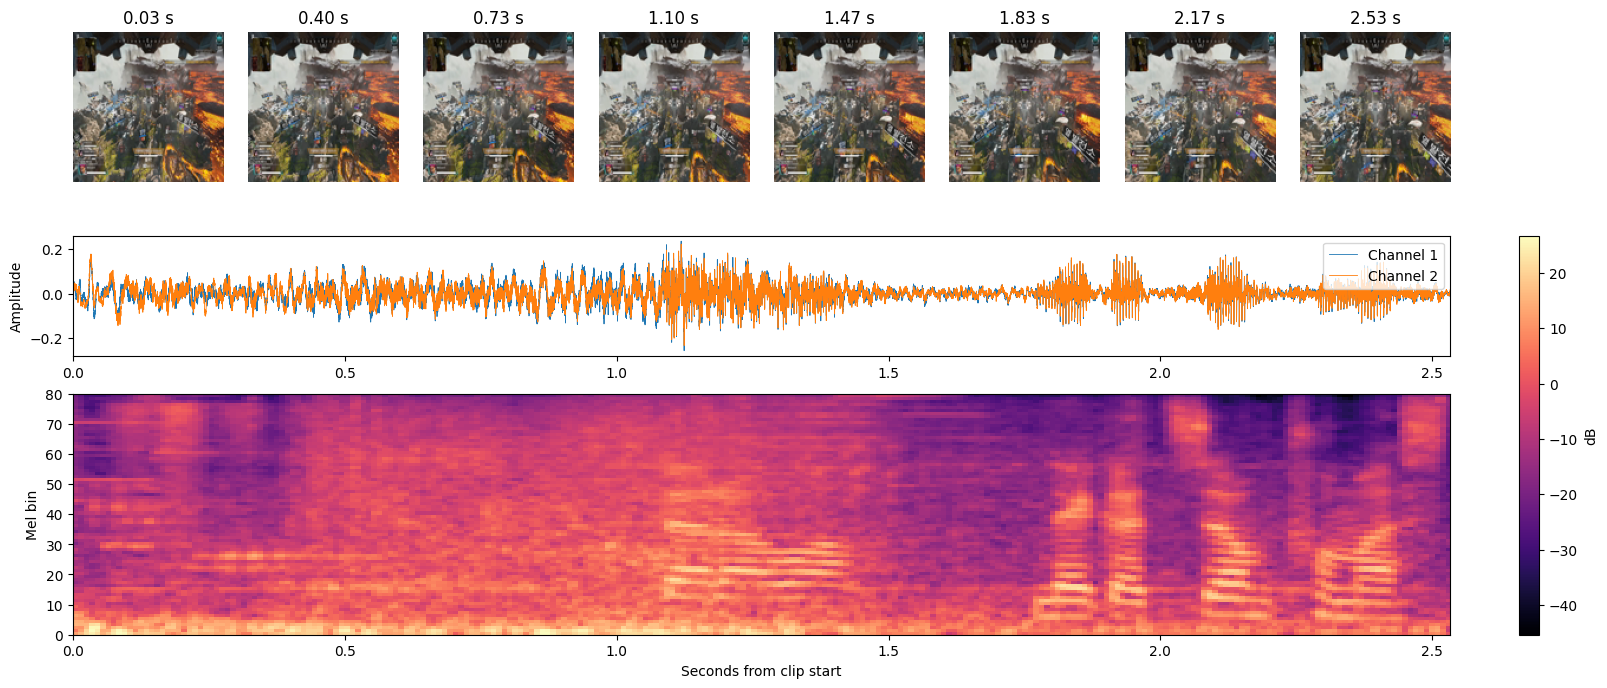

In [9]:
show_av_batch(b)

# Architecture

## Types for Encoders/Decoders

In [10]:
type ActionAudioConditioning = Literal["transition", "past_only"]


class HybridHistoryConfig(BaseModel):
    model_config = ConfigDict(frozen=True, extra="forbid")

    block_pattern: tuple[Literal["kda"], Literal["kda"], Literal["kda"], Literal["softmax"]] = (
        "kda",
        "kda",
        "kda",
        "softmax",
    )
    chunk_size: PositiveInt = 16
    minimum_log_decay: float = Field(default=-5.0, lt=0.0)


class TransformerStageConfig(BaseModel):
    model_config = ConfigDict(frozen=True)

    hidden_dimension: PositiveInt
    heads: PositiveInt
    layers: PositiveInt

    @model_validator(mode="after")
    def validate_attention_heads(self) -> Self:
        if self.hidden_dimension % self.heads:
            raise ValueError("Transformer hidden dimension must be divisible by its head count")
        return self


class WorldModelConfig(BaseModel):
    model_config = ConfigDict(frozen=True)

    action_dimension: PositiveInt
    backbone_attention: Literal["quadratic", "linear", "hybrid_kda"] = "quadratic"
    noise_time_embedding: Literal["sinusoidal", "gaussian_fourier"] = "sinusoidal"
    spatial_grid: tuple[PositiveInt, PositiveInt] | None = None
    hybrid_history: HybridHistoryConfig = Field(default_factory=HybridHistoryConfig)
    backbone: TransformerStageConfig
    diffusion_head: TransformerStageConfig
    mlp_ratio: PositiveFloat = 4.0
    dropout: float = Field(default=0.0, ge=0.0, lt=1.0)

## Kimi Delta Attention

In [11]:
@jaxtyped(typechecker=beartype)
def chunk_kimi_delta_attention(
    queries: Float[Tensor, "batch time head key"],
    keys: Float[Tensor, "batch time head key"],
    values: Float[Tensor, "batch time head value"],
    log_decay: Float[Tensor, "batch time head key"],
    write_strength: Float[Tensor, "batch time head"],
    initial_state: Float[Tensor, "batch head key value"] | None = None,
    chunk_size: int = 16,
) -> tuple[
    Float[Tensor, "batch time head value"],
    Float[Tensor, "batch head key value"],
]:
    batch_size, time_steps, heads, key_dimension = queries.shape
    value_dimension = values.shape[-1]
    if time_steps == 0 or chunk_size <= 0:
        raise ValueError("KDA requires tokens and a positive chunk size")

    # state has to be bxhxkxv
    expected_state_shape = (
        batch_size,
        heads,
        key_dimension,
        value_dimension,
    )
    # little check for device across torch since I don't want to wantonly cast to and across devices, esp since we have DDP for n=2
    invalid_state = initial_state is not None and (
        initial_state.shape != expected_state_shape
        or initial_state.device != queries.device
    )
    if invalid_state:
        raise ValueError(
            f"Expected KDA state {expected_state_shape} on {queries.device}"
        )

    state = (
        queries.new_zeros(expected_state_shape, dtype=torch.float32)
        if initial_state is None
        else initial_state.float()
    )
    output_chunks: list[Tensor] = []
    for chunk_start in range(0, time_steps, chunk_size):
        chunk_end = min(chunk_start + chunk_size, time_steps)
        chunk_queries = rearrange(
            queries[:, chunk_start:chunk_end],
            "batch chunk head key -> batch head chunk key",
        ).float() / math.sqrt(key_dimension)
        # little hack to do the /d_h here instead
        chunk_keys = rearrange(
            keys[:, chunk_start:chunk_end],
            "batch chunk head key -> batch head chunk key",
        ).float()
        chunk_values = rearrange(
            values[:, chunk_start:chunk_end],
            "batch chunk head value -> batch head chunk value",
        ).float()
        chunk_log_decay = rearrange(
            log_decay[:, chunk_start:chunk_end],
            "batch chunk head key -> batch head chunk key",
        ).float()
        chunk_write_strength = rearrange(
            write_strength[:, chunk_start:chunk_end],
            "batch chunk head -> batch head chunk",
        ).float()
        cumulative_log_decay = torch.cumsum(chunk_log_decay, dim=2)
        current_chunk_size = chunk_end - chunk_start
        # same as regular attn causal masking, i.e. for 3 tok (seq) at t=1:
        """
             | x -inf -inf
        Q    | x     x -inf
             | x    x    x

            K
        """
        # if tr, can do a tril like we do
        causal_mask = torch.ones(
            current_chunk_size,
            current_chunk_size,
            dtype=torch.bool,
            device=queries.device,
        ).tril()

        relative_log_decay = (
            cumulative_log_decay[:, :, :, None] - cumulative_log_decay[:, :, None]
        ).masked_fill(~causal_mask[None, None, :, :, None], 0.0)
        key_correlations = einsum(
            chunk_keys,
            chunk_keys,
            torch.exp(relative_log_decay),
            "batch head current key, batch head previous key, "
            "batch head current previous key -> batch head current previous",
        )
        strict_lower_correlations = torch.tril(key_correlations, diagonal=-1)
        identity = torch.eye(
            current_chunk_size, dtype=torch.float32, device=queries.device
        )
        triangular_system = (
            identity[None, None]
            + chunk_write_strength[..., None] * strict_lower_correlations
        )
        weighted_values = chunk_write_strength[..., None] * chunk_values
        weighted_keys = (
            chunk_write_strength[..., None]
            * torch.exp(cumulative_log_decay)
            * chunk_keys
        )

        # lol uh idk how to do this faster on our hardware
        transformed_values = torch.linalg.solve_triangular(
            triangular_system, weighted_values, upper=False
        )
        transformed_keys = torch.linalg.solve_triangular(
            triangular_system, weighted_keys, upper=False
        )

        within_chunk_attention = einsum(
            chunk_queries,
            chunk_keys,
            torch.exp(relative_log_decay),
            "batch head current key, batch head previous key, "
            "batch head current previous key -> batch head current previous",
        )
        within_chunk_attention = torch.tril(within_chunk_attention)
        pseudo_values = transformed_values - torch.matmul(transformed_keys, state)
        previous_state_output = einsum(
            chunk_queries * torch.exp(cumulative_log_decay),
            state,
            "batch head chunk key, batch head key value -> " "batch head chunk value",
        )
        output_chunks.append(
            previous_state_output + torch.matmul(within_chunk_attention, pseudo_values)
        )

        final_log_decay = cumulative_log_decay[:, :, -1]
        state = state * torch.exp(final_log_decay[..., None])
        keys_at_chunk_end = chunk_keys * torch.exp(
            final_log_decay[:, :, None] - cumulative_log_decay
        )
        state = state + einsum(
            keys_at_chunk_end,
            pseudo_values,
            "batch head chunk key, batch head chunk value -> batch head key value",
        )

    output = rearrange(
        torch.cat(output_chunks, dim=2),
        "batch head time value -> batch time head value",
    )
    return output.to(values.dtype), state


class KimiDeltaAttention(nn.Module):
    def __init__(
        self,
        hidden_dimension: int,
        heads: int,
        head_dimension: int,
        chunk_size: int = 16,
        minimum_log_decay: float = -5.0,
    ) -> None:
        super().__init__()
        invalid_configuration = (
            hidden_dimension <= 0
            or heads <= 0
            or head_dimension <= 0
            or chunk_size <= 0
            or minimum_log_decay >= 0.0
        )
        if invalid_configuration:
            raise ValueError(
                "KDA dimensions and chunk size must be positive; decay must be negative"
            )

        projection_dimension = heads * head_dimension
        self.heads = heads
        self.head_dimension = head_dimension
        self.chunk_size = chunk_size
        self.minimum_log_decay = minimum_log_decay
        self.query_projection = nn.Linear(
            hidden_dimension, projection_dimension, bias=False
        )
        self.key_projection = nn.Linear(
            hidden_dimension, projection_dimension, bias=False
        )
        self.value_projection = nn.Linear(
            hidden_dimension, projection_dimension, bias=False
        )
        self.decay_projection = nn.Sequential(
            nn.Linear(hidden_dimension, head_dimension, bias=False),
            nn.Linear(head_dimension, projection_dimension, bias=False),
        )
        self.write_projection = nn.Linear(hidden_dimension, heads, bias=False)
        self.output_gate_projection = nn.Linear(
            hidden_dimension, projection_dimension, bias=False
        )
        self.output_norm = nn.RMSNorm(head_dimension)
        self.output_projection = nn.Linear(
            projection_dimension, hidden_dimension, bias=False
        )

        self.log_decay_scale = nn.Parameter(torch.zeros(heads))
        time_step = torch.exp(
            torch.rand(heads, head_dimension) * (math.log(0.1) - math.log(0.001))
            + math.log(0.001)
        ).clamp(min=0.0001)
        self.decay_bias = nn.Parameter(time_step + torch.log(-torch.expm1(-time_step)))

    @jaxtyped(typechecker=beartype)
    def forward(
        self,
        tokens: Float[Tensor, "batch time hidden"],
        initial_state: Float[Tensor, "batch head state_key state_value"] | None = None,
    ) -> tuple[
        Float[Tensor, "batch time hidden"],
        Float[Tensor, "batch head state_key state_value"],
    ]:
        queries = rearrange(
            self.query_projection(tokens),
            "batch time (head channel) -> batch time head channel",
            head=self.heads,
        )
        keys = rearrange(
            self.key_projection(tokens),
            "batch time (head channel) -> batch time head channel",
            head=self.heads,
        )
        values = rearrange(
            self.value_projection(tokens),
            "batch time (head channel) -> batch time head channel",
            head=self.heads,
        )

        # lazy bum doesnt use his own normalization fns
        queries = functional.normalize(functional.silu(queries), dim=-1)
        keys = functional.normalize(functional.silu(keys), dim=-1)
        values = functional.silu(values)

        decay_logits = rearrange(
            self.decay_projection(tokens),
            "batch time (head channel) -> batch time head channel",
            head=self.heads,
        ).float()
        log_decay = self.minimum_log_decay * torch.sigmoid(
            torch.exp(self.log_decay_scale)[None, None, :, None]
            * (decay_logits + self.decay_bias[None, None])
        )
        write_strength = torch.sigmoid(self.write_projection(tokens).float())
        output, state = chunk_kimi_delta_attention(
            queries,
            keys,
            values,
            log_decay,
            write_strength,
            initial_state,
            self.chunk_size,
        )

        output_gate = torch.sigmoid(
            rearrange(
                self.output_gate_projection(tokens),
                "batch time (head channel) -> batch time head channel",
                head=self.heads,
            )
        )
        output = self.output_norm(output) * output_gate
        output = self.output_projection(
            rearrange(output, "batch time head channel -> batch time (head channel)")
        )
        return output, state

## Transformer

In [12]:
def sinusoidal_timestep_embedding(timesteps: Tensor, dimension: int) -> Tensor:
    return get_timestep_embedding(
        timesteps.reshape(-1).float(),
        dimension,
        flip_sin_to_cos=True,
        downscale_freq_shift=min(1, dimension // 2 - 1),
    )


@jaxtyped(typechecker=beartype)
def frame_position_embeddings(
    reference: Float[Tensor, "..."], dimension: int, start: int, stop: int
) -> Float[Tensor, "position hidden"]:
    return sinusoidal_timestep_embedding(
        torch.arange(start, stop, device=reference.device, dtype=reference.dtype),
        dimension,
    )


# in general, referred to https://docs.pytorch.org/docs/master/generated/torch.nn.MultiheadAttention.html for this
class MultiHeadAttention(nn.Module):
    def __init__(self, dimension: int, heads: int, dropout: float = 0.0) -> None:
        super().__init__()
        if dimension % heads:
            raise ValueError("Attention dimension must be divisible by its head count")
        self.heads = heads
        self.head_dimension = dimension // heads
        self.dropout = dropout
        self.query_projection = nn.Linear(dimension, dimension)
        self.key_projection = nn.Linear(dimension, dimension)
        self.value_projection = nn.Linear(dimension, dimension)
        self.query_norm = nn.RMSNorm(self.head_dimension)
        self.key_norm = nn.RMSNorm(self.head_dimension)
        self.output_projection = nn.Linear(dimension, dimension)

    def forward(
        self,
        query: Tensor,
        key: Tensor,
        value: Tensor,
        attention_mask: Tensor | None = None,
    ) -> Tensor:
        """
        qkv are (3,...) tensors of shape bxqxL where L is seq_len
        need to expand into bxhxqxch so can operate on the channel dim
        see query_proj method, key_norm and value proj
        still uses F.SDPA (with option for attn mask) and returns bxqxL expanded in

        @param query: query tensorfor self-attn
        @param key: key tensor for self-attn
        @param value: value tensor for self-attn
        @param attn_mask: optional attention mask to hide future preds from current state. written to be compat with F.SDPA
        Returns:
            O = A(QK^T/sqrt(d_h)V) which is of shap e b x q x L (L = hxch)

        """
        query_tokens = self.query_norm(
            rearrange(
                self.query_projection(query),
                "batch query (head channel) -> batch head query channel",
                head=self.heads,
            )
        )
        key_tokens = self.key_norm(
            rearrange(
                self.key_projection(key),
                "batch key (head channel) -> batch head key channel",
                head=self.heads,
            )
        )
        value_tokens = rearrange(
            self.value_projection(value),
            "batch key (head channel) -> batch head key channel",
            head=self.heads,
        )
        attended = functional.scaled_dot_product_attention(
            query_tokens,
            key_tokens,
            value_tokens,
            attn_mask=attention_mask,
            dropout_p=self.dropout if self.training else 0.0,
        )
        attended = rearrange(
            attended,
            "batch head query channel -> batch query (head channel)",
        )
        return self.output_projection(attended)


class LinearAttention(nn.Module):
    def __init__(self, dimension: int, heads: int, dropout: float = 0.0) -> None:
        super().__init__()
        if dimension % heads:
            raise ValueError("Attention dimension must be divisible by its head count")
        self.heads = heads
        self.head_dimension = dimension // heads
        self.query_projection = nn.Linear(dimension, dimension, bias=False)
        self.key_projection = nn.Linear(dimension, dimension, bias=False)
        self.value_projection = nn.Linear(dimension, dimension, bias=False)
        self.output_projection = nn.Linear(dimension, dimension, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(
        self,
        query: Tensor,
        key: Tensor,
        value: Tensor,
        causal_prefix_lengths: Tensor | None = None,
    ) -> Tensor:
        query_features = (
            functional.elu(
                rearrange(
                    self.query_projection(query),
                    "batch token (head channel) -> batch head token channel",
                    head=self.heads,
                )
            )
            + 1.0
        )
        key_features = (
            functional.elu(
                rearrange(
                    self.key_projection(key),
                    "batch token (head channel) -> batch head token channel",
                    head=self.heads,
                )
            )
            + 1.0
        )
        values = rearrange(
            self.value_projection(value),
            "batch token (head channel) -> batch head token channel",
            head=self.heads,
        )

        if causal_prefix_lengths is None:
            key_sum = key_features.sum(dim=2, keepdim=True)
            key_values = einsum(
                key_features,
                values,
                "batch head time key, batch head time value -> batch head key value",
            )
            attended = einsum(
                query_features,
                key_values,
                "batch head query key, batch head key value -> batch head query value",
            )
            normalizer = einsum(
                query_features,
                key_sum,
                "batch head query key, batch head singleton key -> batch head query singleton",
            )
        else:
            if causal_prefix_lengths.ndim != 1 or causal_prefix_lengths.shape[0] != query.shape[1]:
                raise ValueError("Causal prefix lengths must provide one value per query token")
            if int(causal_prefix_lengths.min()) < 1 or int(causal_prefix_lengths.max()) > key.shape[1]:
                raise ValueError("Causal prefix lengths fall outside the key sequence")
            prefix_indices = causal_prefix_lengths.to(device=query.device, dtype=torch.long) - 1
            cumulative_keys = key_features.cumsum(dim=2)
            cumulative_key_values = einsum(
                key_features,
                values,
                "batch head time key, batch head time value -> batch head time key value",
            ).cumsum(dim=2)
            selected_keys = cumulative_keys[:, :, prefix_indices]
            selected_key_values = cumulative_key_values[:, :, prefix_indices]
            attended = einsum(
                query_features,
                selected_key_values,
                "batch head query key, batch head query key value -> batch head query value",
            )
            normalizer = einsum(
                query_features,
                selected_keys,
                "batch head query key, batch head query key -> batch head query",
            )[:, :, :, None]

        attended = attended / normalizer.clamp_min(1e-6)
        attended = rearrange(attended, "batch head token channel -> batch token (head channel)")
        return self.output_projection(self.dropout(attended))


class SwiGLUFeedForward(nn.Module):
    def __init__(self, dimension: int, mlp_ratio: float, dropout: float) -> None:
        super().__init__()
        hidden_dimension = int(2 * dimension * mlp_ratio / 3)
        self.input_projection = nn.Linear(dimension, hidden_dimension * 2)
        self.dropout = nn.Dropout(dropout)
        self.output_projection = nn.Linear(hidden_dimension, dimension)

    def forward(self, tokens: Tensor) -> Tensor:
        values, gates = self.input_projection(tokens).chunk(2, dim=-1)
        return self.output_projection(self.dropout(values * functional.silu(gates)))


class AdaptiveAttentionBlock(nn.Module):
    def __init__(
        self,
        dimension: int,
        heads: int,
        mlp_ratio: float,
        dropout: float,
    ) -> None:
        super().__init__()
        self.self_attention = MultiHeadAttention(dimension, heads, dropout)
        self.cross_attention = MultiHeadAttention(dimension, heads, dropout)
        self.feed_forward = SwiGLUFeedForward(dimension, mlp_ratio, dropout)
        self.self_norm = nn.RMSNorm(dimension, elementwise_affine=False)
        self.cross_norm = nn.RMSNorm(dimension, elementwise_affine=False)
        self.feed_forward_norm = nn.RMSNorm(dimension, elementwise_affine=False)
        self.context_norm = nn.RMSNorm(dimension)
        self.dropout = nn.Dropout(dropout)
        self.modulation = nn.Sequential(nn.SiLU(), nn.Linear(dimension, dimension * 9))
        nn.init.zeros_(self.modulation[-1].weight)
        nn.init.zeros_(self.modulation[-1].bias)

    def forward(
        self,
        targets: Tensor,
        context: Tensor,
        condition: Tensor,
        attention_mask: Tensor,
    ) -> Tensor:
        modulation_values = self.modulation(condition).chunk(9, dim=-1)
        self_shift, self_scale, self_gate = modulation_values[:3]
        cross_shift, cross_scale, cross_gate = modulation_values[3:6]
        feed_forward_shift, feed_forward_scale, feed_forward_gate = modulation_values[6:]

        self_input = self.self_norm(targets) * (1 + self_scale) + self_shift
        self_output = self.self_attention(
            self_input,
            self_input,
            self_input,
            attention_mask=attention_mask,
        )
        targets = targets + self.dropout(self_gate * self_output)

        cross_input = self.cross_norm(targets) * (1 + cross_scale) + cross_shift
        normalized_context = self.context_norm(context)
        cross_output = self.cross_attention(
            cross_input,
            normalized_context,
            normalized_context,
        )
        targets = targets + self.dropout(cross_gate * cross_output)

        feed_forward_input = self.feed_forward_norm(targets) * (1 + feed_forward_scale) + feed_forward_shift
        feed_forward_output = self.feed_forward(feed_forward_input)
        return targets + self.dropout(feed_forward_gate * feed_forward_output)

## Affine Functions and Tokenization

In [13]:
import torch
from beartype import beartype

class AudioVisualTokenProjector(nn.Module):
    """
    spatial affine fn, effectively projects from d_v, d_a -> E[1...k]

    """
    def __init__(
        self,
        video_dimension: int,
        audio_dimension: int,
        hidden_dimension: int,
        spatial_grid: tuple[int, int] | None = None,
    ) -> None:
        super().__init__()
        self.video_projection = nn.Linear(video_dimension, hidden_dimension)
        self.audio_projection = nn.Linear(audio_dimension, hidden_dimension)
        self.modality_embedding = nn.Embedding(2, hidden_dimension)
        self.spatial_grid = spatial_grid
        self.hidden_dimension = hidden_dimension
        self.register_buffer("spatial_positions", None, persistent=False)

    @jaxtyped(typechecker=beartype)
    def forward(
        self,
        video: Float[Tensor, "batch time patch video_feature"],
        audio: Float[Tensor, "batch time audio_feature"],
        frame_start: int,
        action_embeddings: Float[Tensor, "batch time hidden"] | None = None,
    ) -> Float[Tensor, "batch token_time hidden"]:
        frame_positions = rearrange(
            frame_position_embeddings(video, self.hidden_dimension, frame_start, frame_start + video.shape[1]),
            "time hidden -> 1 time 1 hidden",
        )
        if action_embeddings is None:
            action_embeddings = video.new_zeros((*video.shape[:2], self.hidden_dimension))
        action_positions = rearrange(
            action_embeddings,
            "batch time hidden -> batch time 1 hidden",
        )
        video_tokens = (
            self.video_projection(video) + self.modality_embedding.weight[0] + frame_positions + action_positions
        )
        if self.spatial_grid is not None:
            if video.shape[2] != self.spatial_grid[0] * self.spatial_grid[1]:
                raise ValueError("Video patches do not match the configured spatial grid")
            if self.spatial_positions is None:
                self.spatial_positions = get_2d_sincos_pos_embed(
                    self.hidden_dimension,
                    self.spatial_grid,
                    device=video.device,
                    output_type="pt",
                ).to(video)
            video_tokens = video_tokens + rearrange(self.spatial_positions, "patch hidden -> 1 1 patch hidden")
        audio_tokens = (
            self.audio_projection(audio)
            + self.modality_embedding.weight[1]
            + frame_positions[:, :, 0]
            + action_positions[:, :, 0]
        )
        return rearrange(
            torch.cat((video_tokens, audio_tokens[:, :, None]), dim=2),
            "batch time token hidden -> batch (time token) hidden",
        )

## Audio Encoder

In [14]:
class CausalLocalAttention(nn.Module):
    """
    causal swiAttn. still (qk^{T}/sqrt(d_h))V but windowed out using a logical and from torch.
    takes ideas from https://arxiv.org/html/2505.02074v1
    @param hidden_dimension int for the latent space to occupy
    @param heads: attn heads
    @param window_steps


    """
    def __init__(self, hidden_dimension: int, heads: int, window_steps: int) -> None:
        super().__init__()
        if hidden_dimension % heads or window_steps <= 0:
            raise ValueError(
                "Attention requires divisible dimensions and a positive window"
            )
        self.heads = heads
        self.window_steps = window_steps
        self.query_projection = nn.Linear(
            hidden_dimension, hidden_dimension, bias=False
        )
        self.key_projection = nn.Linear(hidden_dimension, hidden_dimension, bias=False)
        self.value_projection = nn.Linear(
            hidden_dimension, hidden_dimension, bias=False
        )
        self.output_projection = nn.Linear(
            hidden_dimension, hidden_dimension, bias=False
        )

    @jaxtyped(typechecker=beartype)
    def forward(
        self, tokens: Float[Tensor, "batch time hidden"]
    ) -> Float[Tensor, "batch time hidden"]:
        queries = rearrange(
            self.query_projection(tokens),
            "batch time (head channel) -> batch head time channel",
            head=self.heads,
        )
        keys = rearrange(
            self.key_projection(tokens),
            "batch time (head channel) -> batch head time channel",
            head=self.heads,
        )
        values = rearrange(
            self.value_projection(tokens),
            "batch time (head channel) -> batch head time channel",
            head=self.heads,
        )
        positions = torch.arange(tokens.shape[1], device=tokens.device)
        distance = positions[:, None] - positions[None, :]
        attention_mask = torch.logical_and(
            distance >= 0,
            distance < self.window_steps,
        )
        attended = functional.scaled_dot_product_attention(
            queries,
            keys,
            values,
            attn_mask=attention_mask,
        )
        return self.output_projection(
            rearrange(
                attended,
                "batch head time channel -> batch time (head channel)",
            )
        )


class HybridAudioEncoder(nn.Module):
    def __init__(
        self,
        input_channels: int,
        hidden_dimension: int,
        latent_dimension: int,
        downsample_strides: Sequence[int],
        block_pattern: Sequence[str],
        kda_heads: int,
        kda_head_dimension: int,
        kda_chunk_size: int,
        kda_minimum_log_decay: float,
        attention_heads: int,
        attention_window_steps: int,
    ) -> None:
        """
        setup for waveform -> latent. best way is linear/softmax attn with some ratio
        alternates between kimi delta and transformer layers
        operates on channel_dim
        ratio can be passed as seq but maybe better to parse as a frac non-natively?

        @param input_channels: int how many channels which are for mlp/transformer in
        @param h_dim: int dim of conv output for downsampling waveform
        @param latent_dim: int what dim/size of emb space
        @param downsample_strides: seq of int representing strides of conv for each. need to do a len check
        @param block_pattern: seq(str) like "K","K","K","A","K","K","K","A" for the pattern of blocks of kda vs attn
        @param kda_heads: num_heads for kda
        @param kda_head_dimension:
        @param kda_chunk_size: size of chunk to perform Linear ops on for KDA
        @param kda_minimum_log_decay: smallest amount to log-decay the logits of kda
        @param attention_heads: how many heads to use in softmax attn
        @param attn_window_steps: since we are using causal attn (still softmax attn, but a little faster than naive SDPA) how big do we want the sliding window steps to be?
        """
        super().__init__()
        if not downsample_strides or any(stride <= 0 for stride in downsample_strides):
            raise ValueError("Audio downsample strides must be positive")

        stem_layers: list[nn.Module] = []
        stem_input_channels = input_channels
        for stride in downsample_strides:
            stem_layers.extend(
                (
                    nn.Conv1d(
                        stem_input_channels,
                        hidden_dimension,
                        kernel_size=stride,
                        stride=stride,
                    ),
                    nn.GELU(),
                )
            )
            stem_input_channels = hidden_dimension
        self.stem = nn.Sequential(*stem_layers)
        self.total_stride = math.prod(downsample_strides)

        # whole concept of mixers comes I think from Mamba?
        # https://github.com/state-spaces/mamba/blob/main/mamba_ssm/models/mixer_seq_simple.py
        mixers: list[nn.Module] = []
        for block_kind in block_pattern:
            if block_kind == "kda":
                mixers.append(
                    KimiDeltaAttention(
                        hidden_dimension,
                        kda_heads,
                        kda_head_dimension,
                        kda_chunk_size,
                        kda_minimum_log_decay,
                    )
                )
            elif block_kind == "attention":
                mixers.append(
                    CausalLocalAttention(
                        hidden_dimension,
                        attention_heads,
                        attention_window_steps,
                    )
                )
            else:
                raise ValueError(f"Unknown audio mixer: {block_kind}")
        self.mixers = nn.ModuleList(mixers)
        self.mixer_norms = nn.ModuleList(
            nn.RMSNorm(hidden_dimension) for block_kind in block_pattern
        )
        self.feed_forward_norms = nn.ModuleList(
            nn.RMSNorm(hidden_dimension) for block_kind in block_pattern
        )
        self.feed_forwards = nn.ModuleList(
            nn.Sequential(
                nn.Linear(hidden_dimension, hidden_dimension * 4),
                nn.SiLU(),
                nn.Linear(hidden_dimension * 4, hidden_dimension),
            )
            for block_kind in block_pattern
        )
        self.output_projection = nn.Linear(hidden_dimension, latent_dimension)
        self.kda_block_count = block_pattern.count("kda")

    @jaxtyped(typechecker=beartype)
    def forward(
        self,
        waveform: Float[Tensor, "batch channel sample"],
        initial_states: list[Tensor] | None = None,
    ) -> tuple[Float[Tensor, "batch time latent"], list[Tensor]]:
        """
        takes in waveform (tensor) with some initial states and runs fwd pass.
        @param waveform: float tensor of shape bxcxsample (or audio_sample, depending on which file you look at)
        @param initial_states: list of tensors for initializing the kda state matrix. can be optional.

        Returns:
            latent representation which is 3 tensor of b x t x l
            l is inherited from the model class, same as t
            also returns the state matrix for next states
        """
        if waveform.shape[-1] % self.total_stride:
            raise ValueError(
                f"Audio samples must be divisible by encoder stride {self.total_stride}"
            )
        if initial_states is not None and len(initial_states) != self.kda_block_count:
            raise ValueError(f"Expected {self.kda_block_count} KDA states")

        tokens = rearrange(
            self.stem(waveform), "batch hidden time -> batch time hidden"
        )
        next_states: list[Tensor] = []
        # I am not sure if there is a "smarter" way to do iteration through this than a counter and enumerate. maybe something with zip?
        # for now, counter = 0, counter+=1 if valid idx else throw err
        state_index = 0
        for mixer_index, mixer in enumerate(self.mixers):
            normalized = self.mixer_norms[mixer_index](tokens)
            if isinstance(mixer, KimiDeltaAttention):
                initial_state = (
                    None if initial_states is None else initial_states[state_index]
                )
                mixed, next_state = mixer(normalized, initial_state)
                next_states.append(next_state)
                state_index += 1
            elif isinstance(mixer, CausalLocalAttention):
                mixed = mixer(normalized)
            else:
                raise TypeError(f"Unsupported mixer type: {type(mixer).__name__}")
            tokens = tokens + mixed
            tokens = tokens + self.feed_forwards[mixer_index](
                self.feed_forward_norms[mixer_index](tokens)
            )
        return self.output_projection(tokens), next_states

## Audio Decoder
(for seeing what our model is hearing, not used during optimization)

In [15]:
class CausalAudioDecoder(nn.Module):
    def __init__(
        self, latent_dimension: int, output_channels: int, samples_per_token: int
    ) -> None:
        super().__init__()
        if output_channels <= 0 or samples_per_token <= 0:
            raise ValueError("Audio decoder dimensions must be positive")
        self.output_channels = output_channels
        self.samples_per_token = samples_per_token
        self.output_projection = nn.Linear(
            latent_dimension, output_channels * samples_per_token
        )

    @jaxtyped(typechecker=beartype)
    def forward(
        self,
        latents: Float[Tensor, "batch time latent"],
    ) -> Float[Tensor, "batch channel sample"]:
        samples = self.output_projection(latents)
        return rearrange(
            samples,
            "batch time (channel sample) -> batch channel (time sample)",
            channel=self.output_channels,
            sample=self.samples_per_token,
        )

## Video Encoder


In [16]:
class DinoVideoEncoder(nn.Module):
    def __init__(
        self,
        model_id: str,
        pretrained: bool,
        image_size: int,
        layer_numbers: Sequence[int],
        mean: Sequence[float],
        standard_deviation: Sequence[float],
        frozen: bool = True,
    ) -> None:
        """
        in general, dinoV2/V3 returns mean pooled lat of cls_tok, r_1 .. r_4
        you can check fn_signature and look at a sample output
        norm is imagenet norm usually
        but could also be 3 ch of 0.5 (not really standard)
        """
        super().__init__()
        if not layer_numbers or min(layer_numbers) < 1:
            raise ValueError("DINO layer numbers are one-based and must be positive")
        if len(mean) != 3 or len(standard_deviation) != 3:
            raise ValueError("DINO normalization requires three channels")
        self.backbone = cast(
            VisionTransformer,
            timm.create_model(
                model_id,
                pretrained=pretrained,
                num_classes=0,
                img_size=image_size,
            ),
        )
        self.layer_indices = [layer_number - 1 for layer_number in layer_numbers]
        self.image_size = image_size
        self.register_buffer(
            "mean",
            torch.tensor(mean, dtype=torch.float32)[None, :, None, None],
            persistent=False,
        )
        self.register_buffer(
            "standard_deviation",
            torch.tensor(standard_deviation, dtype=torch.float32)[None, :, None, None],
            persistent=False,
        )
        self.frozen = frozen
        self.requires_grad_(not frozen)
        if frozen:
            self.eval()

    @jaxtyped(typechecker=beartype)
    def forward(
        self, frames: Float[Tensor, "batch time channel height width"]
    ) -> Float[Tensor, "batch time patch feature"]:
        batch_size, time_steps = frames.shape[:2]
        images = rearrange(
            frames,
            "batch time channel height width -> (batch time) channel height width",
        )
        if images.shape[-2:] != (self.image_size, self.image_size):
            images = functional.interpolate(
                images,
                size=(self.image_size, self.image_size),
                mode="bilinear",
                align_corners=False,
            )
        images = (images - self.mean) / self.standard_deviation
        gradient_context = torch.no_grad() if self.frozen else nullcontext()
        with gradient_context:
            layer_features = cast(
                list[Tensor],
                self.backbone.forward_intermediates(
                    images,
                    indices=self.layer_indices,
                    norm=True,
                    output_fmt="NLC",
                    intermediates_only=True,
                ),
            )
            patch_features = reduce(
                torch.stack(layer_features),
                "layer image patch feature -> image patch feature",
                "mean",
            )
        return rearrange(
            patch_features,
            "(batch time) patch feature -> batch time patch feature",
            batch=batch_size,
            time=time_steps,
        )

## Video Decoder

In [17]:
class DecoderResidualBlock(nn.Module):
    def __init__(self, channels: int, normalization_groups: int) -> None:
        super().__init__()
        self.block = nn.Sequential(
            nn.GroupNorm(normalization_groups, channels),
            nn.SiLU(),
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.GroupNorm(normalization_groups, channels),
            nn.SiLU(),
            nn.Conv2d(channels, channels, 3, padding=1),
        )

    def forward(self, features: Tensor) -> Tensor:
        return features + self.block(features)


class DecoderUpsampleBlock(nn.Module):
    def __init__(
        self, input_channels: int, output_channels: int, normalization_groups: int
    ) -> None:
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(input_channels, output_channels, 3, padding=1),
            nn.GroupNorm(normalization_groups, output_channels),
            nn.SiLU(),
        )

    def forward(self, features: Tensor) -> Tensor:
        features = functional.interpolate(
            features,
            scale_factor=2.0,
            mode="bilinear",
            align_corners=False,
        )
        return self.block(features)


class DinoVideoDecoder(nn.Module):
    def __init__(
        self,
        feature_dimension: int,
        hidden_dimension: int,
        upsample_channels: Sequence[int],
        residual_blocks: int,
        normalization_groups: int,
        patch_grid_size: int,
    ) -> None:
        super().__init__()
        channels = (hidden_dimension, *upsample_channels)
        if any(channel % normalization_groups for channel in channels):
            raise ValueError(
                "Decoder channels must divide evenly into normalization groups"
            )
        if residual_blocks <= 0 or patch_grid_size <= 0:
            raise ValueError("Decoder block count and patch grid must be positive")
        self.patch_grid_size = patch_grid_size
        self.input_projection = nn.Conv2d(feature_dimension, hidden_dimension, 1)
        self.residual_stack = nn.Sequential(
            *(
                DecoderResidualBlock(hidden_dimension, normalization_groups)
                for block_index in range(residual_blocks)
            )
        )
        decoder_blocks: list[nn.Module] = []
        input_channels = hidden_dimension
        for output_channels in upsample_channels:
            decoder_blocks.extend(
                (
                    DecoderUpsampleBlock(
                        input_channels,
                        output_channels,
                        normalization_groups,
                    ),
                    DecoderResidualBlock(output_channels, normalization_groups),
                )
            )
            input_channels = output_channels
        self.upsampler = nn.Sequential(*decoder_blocks)
        self.output_head = nn.Sequential(
            nn.Conv2d(input_channels, input_channels, 3, padding=1),
            nn.SiLU(),
            nn.Conv2d(input_channels, 3, 3, padding=1),
            nn.Sigmoid(),
        )

    @jaxtyped(typechecker=beartype)
    def forward(
        self,
        latents: Float[Tensor, "batch time patch feature"],
    ) -> Float[Tensor, "batch time channel height width"]:
        if latents.shape[2] != self.patch_grid_size**2:
            raise ValueError(f"Expected {self.patch_grid_size**2} DINO patch tokens")
        feature_maps = rearrange(
            latents,
            "batch time (height width) feature -> (batch time) feature height width",
            height=self.patch_grid_size,
            width=self.patch_grid_size,
        )
        images = self.output_head(
            self.upsampler(self.residual_stack(self.input_projection(feature_maps)))
        )
        return rearrange(
            images,
            "(batch time) channel height width -> batch time channel height width",
            batch=latents.shape[0],
            time=latents.shape[1],
        )

## Wide DDT Head

In [18]:
class AdaptiveOutputProjection(nn.Module):
    def __init__(self, hidden_dimension: int, output_dimension: int) -> None:
        """
        stole from Boyang and changed to look a little clener.
        modulation is silu -> affine_fn for 2x h_dim
        zero init w,b for all since initially want to lean on the frozen representations

        """
        super().__init__()
        self.normalization = nn.RMSNorm(hidden_dimension, elementwise_affine=False)
        self.modulation = nn.Sequential(
            nn.SiLU(),
            nn.Linear(hidden_dimension, hidden_dimension * 2),
        )
        self.output_projection = nn.Linear(hidden_dimension, output_dimension)
        nn.init.zeros_(self.modulation[-1].weight)
        nn.init.zeros_(self.modulation[-1].bias)
        nn.init.zeros_(self.output_projection.weight)
        nn.init.zeros_(self.output_projection.bias)

    def forward(self, tokens: Tensor, condition: Tensor) -> Tensor:
        shift, scale = self.modulation(condition).chunk(2, dim=-1)
        return self.output_projection(self.normalization(tokens) * (1 + scale) + shift)


class AudioVisualDDTHead(nn.Module):
    def __init__(
        self,
        video_dimension: int,
        audio_dimension: int,
        action_dimension: int,
        backbone_dimension: int,
        hidden_dimension: int,
        heads: int,
        layers: int,
        mlp_ratio: float,
        dropout: float,
        spatial_grid: tuple[int, int] | None = None,
    ) -> None:
        super().__init__()
        self.target_tokens = AudioVisualTokenProjector(
            video_dimension,
            audio_dimension,
            hidden_dimension,
            spatial_grid,
        )
        self.context_tokens = AudioVisualTokenProjector(
            video_dimension,
            audio_dimension,
            hidden_dimension,
            spatial_grid,
        )
        self.action_projection = nn.Linear(
            action_dimension,
            hidden_dimension,
            bias=False,
        )
        self.condition_projection = nn.Linear(backbone_dimension, hidden_dimension)
        self.blocks = nn.ModuleList(
            AdaptiveAttentionBlock(hidden_dimension, heads, mlp_ratio, dropout) for layer_index in range(layers)
        )
        self.video_output = AdaptiveOutputProjection(
            hidden_dimension,
            video_dimension,
        )
        self.audio_output = AdaptiveOutputProjection(
            hidden_dimension,
            audio_dimension,
        )

    def forward(
        self,
        noisy_video: Tensor,
        noisy_audio: Tensor,
        context_video: Tensor,
        context_audio: Tensor,
        target_actions: Tensor,
        backbone_targets: Tensor,
        backbone_condition: Tensor,
        attention_mask: Tensor,
    ) -> tuple[Tensor, Tensor]:
        target_steps = noisy_video.shape[1]
        video_patches = noisy_video.shape[2]
        targets = self.target_tokens(
            noisy_video,
            noisy_audio,
            0,
            self.action_projection(target_actions),
        )
        context = self.context_tokens(context_video, context_audio, -context_video.shape[1])
        condition = self.condition_projection(
            functional.silu(backbone_targets + rearrange(backbone_condition, "batch hidden -> batch 1 hidden"))
        )
        for block in self.blocks:
            targets = block(targets, context, condition, attention_mask)

        tokens_per_step = video_patches + 1
        predictions = rearrange(
            targets,
            "batch (time token) hidden -> batch time token hidden",
            time=target_steps,
            token=tokens_per_step,
        )
        output_condition = rearrange(
            condition,
            "batch (time token) hidden -> batch time token hidden",
            time=target_steps,
            token=tokens_per_step,
        )
        video_velocity = self.video_output(
            predictions[:, :, :video_patches],
            output_condition[:, :, :video_patches],
        )
        audio_velocity = self.audio_output(
            predictions[:, :, -1],
            output_condition[:, :, -1],
        )
        return video_velocity, audio_velocity

## Latent Action Model

In [19]:
class LatentActionModel(nn.Module):
    def __init__(
        self,
        video_dimension: int,
        audio_dimension: int,
        hidden_dimension: int,
        action_dimension: int,
        code_count: int,
        ema_decay: float,
        ema_epsilon: float,
        audio_conditioning: ActionAudioConditioning = "transition",
    ) -> None:
        """
        VQ-VAE for operating in a set action dim.
        insp from Jack Lu fro m Mengye's lab who did this for xHC
        https://arxiv.org/pdf/2610.03039

        """
        super().__init__()
        if code_count < 2 or not 0.0 <= ema_decay < 1.0 or ema_epsilon <= 0.0:
            raise ValueError("Latent-action codebook settings are invalid")
        transition_dimension = 2 * (video_dimension + audio_dimension)
        self.encoder = nn.Sequential(
            nn.Linear(transition_dimension, hidden_dimension),
            nn.SiLU(),
            nn.Linear(hidden_dimension, action_dimension),
        )
        codebook = functional.normalize(torch.randn(code_count, action_dimension), dim=-1)
        self.register_buffer("codebook", codebook)
        self.register_buffer("ema_counts", torch.ones(code_count))
        self.register_buffer("ema_sums", codebook.clone())
        self.code_count = code_count
        self.ema_decay = ema_decay
        self.ema_epsilon = ema_epsilon
        self.audio_conditioning = audio_conditioning

    @jaxtyped(typechecker=beartype)
    def sequence_actions(
        self,
        video: Float[Tensor, "batch time patch video_feature"],
        audio: Float[Tensor, "batch time audio_feature"],
        context_steps: int,
    ) -> tuple[
        Float[Tensor, "batch target_time action"],
        Int[Tensor, "batch target_time"],
        Float[Tensor, "batch target_time action"],
        Float[Tensor, ""],
    ]:
        """mask future by using ctx as audio"""
        previous_audio = audio[:, context_steps - 1 : -1]
        next_audio = audio[:, context_steps:]
        if self.audio_conditioning == "past_only":
            previous_audio = repeat(
                audio[:, context_steps - 1],
                "batch feature -> batch time feature",
                time=audio.shape[1] - context_steps,
            )
            next_audio = previous_audio
        return self(video[:, context_steps - 1 : -1], video[:, context_steps:], previous_audio, next_audio)

    @jaxtyped(typechecker=beartype)
    def forward(
        self,
        previous_video: Float[Tensor, "batch time patch video_feature"],
        next_video: Float[Tensor, "batch time patch video_feature"],
        previous_audio: Float[Tensor, "batch time audio_feature"],
        next_audio: Float[Tensor, "batch time audio_feature"],
    ) -> tuple[
        Float[Tensor, "batch time action"],
        Int[Tensor, "batch time"],
        Float[Tensor, "batch time action"],
        Float[Tensor, ""],
    ]:
        if previous_video.shape != next_video.shape or previous_audio.shape != next_audio.shape:
            raise ValueError("Latent-action transition pairs must have matching shapes")
        if previous_video.shape[:2] != previous_audio.shape[:2]:
            raise ValueError("Latent-action audio and video times must align")
        pooled_previous_video = reduce(previous_video, "batch time patch feature -> batch time feature", "mean")
        pooled_next_video = reduce(next_video, "batch time patch feature -> batch time feature", "mean")
        transition = torch.cat(
            (pooled_previous_video, pooled_next_video, previous_audio, next_audio),
            dim=-1,
        )
        encoded = self.encoder(transition)
        distances = reduce(
            (encoded[:, :, None] - self.codebook[None, None]).square(),
            "batch time code action -> batch time code",
            "sum",
        )
        code_ids = distances.argmin(dim=-1)
        selected_codes = self.codebook[code_ids]
        quantized = encoded + (selected_codes - encoded).detach()
        # TODO: ablate inclusion of commitment_loss, in general not fan of incl loss inline
        commitment_loss = functional.mse_loss(encoded, selected_codes.detach())
        return quantized, code_ids, encoded, commitment_loss

    @torch.no_grad()
    @jaxtyped(typechecker=beartype)
    def update_codebook(
        self,
        encoded: Float[Tensor, "batch time action"],
        code_ids: Int[Tensor, "batch time"],
    ) -> None:
        assignments = functional.one_hot(code_ids, self.code_count).to(encoded)
        counts = reduce(assignments, "batch time code -> code", "sum")
        sums = einsum(
            assignments,
            encoded,
            "batch time code, batch time action -> code action",
        )
        self.ema_counts.mul_(self.ema_decay).add_(counts, alpha=1.0 - self.ema_decay)
        self.ema_sums.mul_(self.ema_decay).add_(sums, alpha=1.0 - self.ema_decay)
        total_count = self.ema_counts.sum()
        normalized_counts = (
            (self.ema_counts + self.ema_epsilon) / (total_count + self.code_count * self.ema_epsilon) * total_count
        )
        self.codebook.copy_(self.ema_sums / normalized_counts[:, None])

    @jaxtyped(typechecker=beartype)
    def lookup(self, code_ids: Int[Tensor, "batch time"]) -> Float[Tensor, "batch time action"]:
        if torch.any(torch.logical_or(code_ids < 0, code_ids >= self.code_count)):
            raise ValueError(f"Latent action IDs must be in [0, {self.code_count})")
        return self.codebook[code_ids]

## Hybrid Model

In [20]:
class HistoryMixerBlock(nn.Module):
    def __init__(
        self,
        dimension: int,
        mlp_ratio: float,
        dropout: float,
        attention: LinearAttention | KimiDeltaAttention | MultiHeadAttention,
    ) -> None:
        super().__init__()
        self.attention_norm = nn.RMSNorm(dimension)
        self.attention = attention
        self.feed_forward_norm = nn.RMSNorm(dimension)
        self.feed_forward = SwiGLUFeedForward(dimension, mlp_ratio, dropout)
        self.dropout = nn.Dropout(dropout)

    @jaxtyped(typechecker=beartype)
    def forward(
        self,
        tokens: Float[Tensor, "batch time hidden"],
        causal_prefix_lengths: Int[Tensor, "time"],  # noqa: F821
    ) -> Float[Tensor, "batch time hidden"]:
        normalized = self.attention_norm(tokens)
        if isinstance(self.attention, LinearAttention):
            attended = self.attention(normalized, normalized, normalized, causal_prefix_lengths)
        elif isinstance(self.attention, KimiDeltaAttention):
            attended = self.attention(normalized)[0]
        else:
            positions = torch.arange(tokens.shape[1], device=tokens.device)
            attention_mask = positions[None, :] < causal_prefix_lengths[:, None]
            attended = self.attention(normalized, normalized, normalized, attention_mask=attention_mask)
        tokens = tokens + self.dropout(attended)
        return tokens + self.dropout(self.feed_forward(self.feed_forward_norm(tokens)))


class AudioVisualHistoryMixer(nn.Module):
    def __init__(
        self,
        video_dimension: int,
        audio_dimension: int,
        action_dimension: int,
        hidden_dimension: int,
        heads: int,
        layers: int,
        mlp_ratio: float,
        dropout: float,
        config: HybridHistoryConfig | None = None,
    ) -> None:
        if config is not None and (layers < 1 or layers % len(config.block_pattern)):
            raise ValueError("Hybrid history requires complete three-KDA/one-softmax cycles")
        super().__init__()
        self.hidden_dimension = hidden_dimension
        self.video_projection = nn.Linear(video_dimension, hidden_dimension)
        self.audio_projection = nn.Linear(audio_dimension, hidden_dimension)
        self.action_projection = nn.Linear(action_dimension, hidden_dimension, bias=False)
        self.modality_norm = nn.RMSNorm(hidden_dimension)
        self.blocks = nn.ModuleList()
        for layer_index in range(layers):
            if config is None:
                attention = LinearAttention(hidden_dimension, heads, dropout)
            elif config.block_pattern[layer_index % len(config.block_pattern)] == "kda":
                attention = KimiDeltaAttention(
                    hidden_dimension, heads, hidden_dimension // heads, config.chunk_size, config.minimum_log_decay
                )
            else:
                attention = MultiHeadAttention(hidden_dimension, heads, dropout)
            self.blocks.append(HistoryMixerBlock(hidden_dimension, mlp_ratio, dropout, attention))

    def frame_tokens(
        self,
        video: Tensor,
        audio: Tensor,
        action_embeddings: Tensor,
        frame_start: int,
    ) -> Tensor:
        video_state = self.video_projection(video).mean(dim=2)
        audio_state = self.audio_projection(audio)
        positions = frame_position_embeddings(video, self.hidden_dimension, frame_start, frame_start + video.shape[1])
        position_state = rearrange(positions, "time hidden -> 1 time hidden")
        return self.modality_norm(video_state + audio_state + action_embeddings + position_state)

    def forward(
        self,
        context_video: Tensor,
        context_audio: Tensor,
        target_video: Tensor,
        target_audio: Tensor,
        target_actions: Tensor,
        context_actions: Tensor | None = None,
    ) -> tuple[Tensor, Tensor]:
        context_steps = context_video.shape[1]
        context_tokens = self.frame_tokens(
            context_video,
            context_audio,
            self.context_action_embeddings(context_video, context_actions),
            -context_steps,
        )
        target_tokens = self.frame_tokens(target_video, target_audio, self.action_projection(target_actions), 0)
        tokens = torch.cat((context_tokens, target_tokens), dim=1)
        causal_prefix_lengths = torch.arange(1, tokens.shape[1] + 1, device=tokens.device)
        for block in self.blocks:
            tokens = block(tokens, causal_prefix_lengths)
        return tokens[:, context_steps:], tokens[:, context_steps - 1]

    @jaxtyped(typechecker=beartype)
    def context_action_embeddings(
        self,
        context_video: Float[Tensor, "batch context_time patch video_feature"],
        context_actions: Float[Tensor, "batch context_time action"] | None,
    ) -> Float[Tensor, "batch context_time hidden"]:
        if context_actions is None:
            return context_video.new_zeros((*context_video.shape[:2], self.hidden_dimension))
        if context_actions.shape != (
            *context_video.shape[:2],
            self.action_projection.in_features,
        ):
            raise ValueError("Previous executed actions must align with observation history")
        return self.action_projection(context_actions)

    @jaxtyped(typechecker=beartype)
    def encode_context(
        self,
        context_video: Float[Tensor, "batch context_time patch video_feature"],
        context_audio: Float[Tensor, "batch context_time audio_feature"],
        context_actions: Float[Tensor, "batch context_time action"] | None = None,
    ) -> Float[Tensor, "batch hidden"]:
        tokens = self.frame_tokens(
            context_video,
            context_audio,
            self.context_action_embeddings(context_video, context_actions),
            -context_video.shape[1],
        )
        causal_prefix_lengths = torch.arange(1, tokens.shape[1] + 1, device=tokens.device)
        for block in self.blocks:
            tokens = block(tokens, causal_prefix_lengths)
        return tokens[:, -1]

## AV Flow World Model

In [21]:
class AudioVisualFlowPredictor(nn.Module):
    def __init__(
        self,
        video_dimension: int,
        audio_dimension: int,
        action_dimension: int,
        backbone_hidden_dimension: int,
        backbone_heads: int,
        backbone_layers: int,
        diffusion_head_hidden_dimension: int,
        diffusion_head_heads: int,
        diffusion_head_layers: int,
        mlp_ratio: float,
        dropout: float,
        backbone_attention: str = "quadratic",
        hybrid_history: HybridHistoryConfig | None = None,
        noise_time_embedding: str = "sinusoidal",
        spatial_grid: tuple[int, int] | None = None,
    ) -> None:
        super().__init__()
        self.backbone_hidden_dimension = backbone_hidden_dimension
        if noise_time_embedding not in {"sinusoidal", "gaussian_fourier"}:
            raise ValueError("Unknown noise time embedding")
        self.noise_time_embedding = noise_time_embedding
        self.noise_time_projection = (
            GaussianFourierProjection(
                backbone_hidden_dimension // 2,
                scale=1.0,
                set_W_to_weight=False,
                log=False,
            )
            if noise_time_embedding == "gaussian_fourier"
            else nn.Identity()
        )
        self.null_action = nn.Parameter(torch.zeros(action_dimension))
        self.backbone_target_tokens = AudioVisualTokenProjector(
            video_dimension,
            audio_dimension,
            backbone_hidden_dimension,
            spatial_grid,
        )
        self.backbone_context_tokens = AudioVisualTokenProjector(
            video_dimension,
            audio_dimension,
            backbone_hidden_dimension,
            spatial_grid,
        )
        self.backbone_action_projection = nn.Linear(
            action_dimension,
            backbone_hidden_dimension,
            bias=False,
        )
        self.outcome_head = nn.Sequential(
            nn.RMSNorm(backbone_hidden_dimension),
            nn.Linear(backbone_hidden_dimension, backbone_hidden_dimension * 2),
            nn.SiLU(),
            nn.Linear(backbone_hidden_dimension * 2, 2),
        )
        self.start_time_embedding = nn.Sequential(
            nn.Linear(backbone_hidden_dimension, backbone_hidden_dimension * 4),
            nn.SiLU(),
            nn.Linear(backbone_hidden_dimension * 4, backbone_hidden_dimension),
        )
        self.duration_embedding = nn.Sequential(
            nn.Linear(backbone_hidden_dimension, backbone_hidden_dimension * 4),
            nn.SiLU(),
            nn.Linear(backbone_hidden_dimension * 4, backbone_hidden_dimension),
        )
        if backbone_attention not in {"quadratic", "linear", "hybrid_kda"}:
            raise ValueError("Unknown backbone attention")
        self.backbone_attention = backbone_attention
        self.backbone_blocks = nn.ModuleList(
            AdaptiveAttentionBlock(
                backbone_hidden_dimension,
                backbone_heads,
                mlp_ratio,
                dropout,
            )
            for layer_index in range(backbone_layers if backbone_attention != "hybrid_kda" else 0)
        )
        if backbone_attention == "hybrid_kda" and hybrid_history is None:
            raise ValueError("Hybrid KDA history requires its block settings")
        self.linear_mixer = AudioVisualHistoryMixer(
            video_dimension,
            audio_dimension,
            action_dimension,
            backbone_hidden_dimension,
            backbone_heads,
            backbone_layers,
            mlp_ratio,
            dropout,
            hybrid_history if backbone_attention == "hybrid_kda" else None,
        )
        self.diffusion_head = AudioVisualDDTHead(
            video_dimension,
            audio_dimension,
            action_dimension,
            backbone_hidden_dimension,
            diffusion_head_hidden_dimension,
            diffusion_head_heads,
            diffusion_head_layers,
            mlp_ratio,
            dropout,
            spatial_grid,
        )

    @jaxtyped(typechecker=beartype)
    def noise_time_features(self, time: Float[Tensor, "batch"]) -> Float[Tensor, "batch hidden"]:  # noqa: F821
        if self.noise_time_embedding == "gaussian_fourier":
            return self.noise_time_projection(time)
        return sinusoidal_timestep_embedding(time, self.backbone_hidden_dimension)

    @jaxtyped(typechecker=beartype)
    def predict_transition_outcomes(
        self,
        context_video: Float[Tensor, "batch context_time patch video_feature"],
        context_audio: Float[Tensor, "batch context_time audio_feature"],
        actions: Float[Tensor, "batch target_time action"],
        context_actions: Float[Tensor, "batch context_time action"] | None = None,
    ) -> tuple[
        Float[Tensor, "batch target_time"],
        Float[Tensor, "batch target_time"],
    ]:
        if context_video.shape[:2] != context_audio.shape[:2]:
            raise ValueError("Context audio and video times must align")
        if self.backbone_attention in {"linear", "hybrid_kda"}:
            pooled_context = self.linear_mixer.encode_context(context_video, context_audio, context_actions)
        else:
            context_steps = context_video.shape[1]
            context_tokens = self.backbone_context_tokens(context_video, context_audio, -context_steps)
            pooled_context = rearrange(
                context_tokens,
                "batch (time token) hidden -> batch time token hidden",
                time=context_steps,
            )[:, -1].mean(dim=1)
        outcome_tokens = rearrange(pooled_context, "batch hidden -> batch 1 hidden") + self.backbone_action_projection(
            actions
        )
        outcomes = self.outcome_head(outcome_tokens)
        return outcomes[:, :, 0], outcomes[:, :, 1]

    @jaxtyped(typechecker=beartype)
    def condition_actions(
        self,
        video: Float[Tensor, "batch target_time patch video_feature"],
        actions: Float[Tensor, "batch target_time action"] | None,
    ) -> Float[Tensor, "batch target_time action"]:
        expected_shape = (*video.shape[:2], self.null_action.shape[0])
        if actions is not None:
            if actions.shape != expected_shape:
                raise ValueError(f"Expected action conditions shaped {torch.Size(expected_shape)}")
            return actions
        return repeat(
            self.null_action,
            "action -> batch time action",
            batch=video.shape[0],
            time=video.shape[1],
        )

    @jaxtyped(typechecker=beartype)
    def forward(
        self,
        noisy_video: Float[Tensor, "batch target_time patch video_feature"],
        noisy_audio: Float[Tensor, "batch target_time audio_feature"],
        start_time: Float[Tensor, "batch"],  # noqa: F821
        end_time: Float[Tensor, "batch"],  # noqa: F821
        context_video: Float[Tensor, "batch context_time patch video_feature"],
        context_audio: Float[Tensor, "batch context_time audio_feature"],
        actions: Float[Tensor, "batch target_time action"] | None,
        context_actions: Float[Tensor, "batch context_time action"] | None = None,
    ) -> tuple[
        Float[Tensor, "batch target_time patch video_feature"],
        Float[Tensor, "batch target_time audio_feature"],
    ]:
        if noisy_video.shape[:2] != noisy_audio.shape[:2]:
            raise ValueError("Target audio and video times must align")
        if context_video.shape[:2] != context_audio.shape[:2]:
            raise ValueError("Context audio and video times must align")
        if torch.any(end_time < start_time):
            raise ValueError("Flow end time must not precede start time")

        batch_size, target_steps, video_patches = noisy_video.shape[:3]
        context_steps = context_video.shape[1]
        target_actions = self.condition_actions(noisy_video, actions)
        if context_actions is not None and context_actions.shape != (
            batch_size,
            context_steps,
            self.null_action.shape[0],
        ):
            raise ValueError("Previous executed actions must align with observation history")
        tokens_per_step = video_patches + 1
        frame_indices = repeat(
            torch.arange(target_steps, device=noisy_video.device),
            "time -> (time token)",
            token=tokens_per_step,
        )
        attention_mask = frame_indices[None, :] <= frame_indices[:, None]
        condition = self.start_time_embedding(self.noise_time_features(start_time))
        condition = condition + self.duration_embedding(self.noise_time_features(end_time - start_time))
        if self.backbone_attention in {"linear", "hybrid_kda"}:
            mixed_targets = self.linear_mixer(
                context_video,
                context_audio,
                noisy_video,
                noisy_audio,
                target_actions,
                context_actions,
            )[0]
            mixed_targets = mixed_targets + rearrange(condition, "batch hidden -> batch 1 hidden")
            targets = repeat(
                mixed_targets,
                "batch time hidden -> batch (time token) hidden",
                token=tokens_per_step,
            )
        else:
            targets = self.backbone_target_tokens(
                noisy_video,
                noisy_audio,
                0,
                self.backbone_action_projection(target_actions),
            )
            context = self.backbone_context_tokens(
                context_video,
                context_audio,
                -context_steps,
                None if context_actions is None else self.backbone_action_projection(context_actions),
            )
            global_condition = rearrange(condition, "batch hidden -> batch 1 hidden")
            for block in self.backbone_blocks:
                targets = block(targets, context, global_condition, attention_mask)

        return self.diffusion_head(
            noisy_video,
            noisy_audio,
            context_video,
            context_audio,
            target_actions,
            targets,
            condition,
            attention_mask,
        )

## Normalization

In [22]:
class FrozenChannelNormalizer(nn.Module):
    @jaxtyped(typechecker=beartype)
    def __init__(
        self,
        mean: Float[Tensor, "channel"],  # noqa: F821
        standard_deviation: Float[Tensor, "channel"],  # noqa: F821
    ) -> None:
        super().__init__()
        if mean.shape != standard_deviation.shape:
            raise ValueError("Mean and standard deviation shapes differ")
        # I thikn this is still the way to check if anything in tensor adheres to some condition, maybe torch.where is better?
        if torch.any(standard_deviation <= 0.0):
            raise ValueError("Every channel must have positive standard deviation")
        self.register_buffer("mean", mean.detach().clone())
        self.register_buffer("standard_deviation", standard_deviation.detach().clone())

    @jaxtyped(typechecker=beartype)
    def forward(self, latents: Float[Tensor, "*tokens channel"]) -> Float[Tensor, "*tokens channel"]:
        # eff z -scaling (x - mu) / sqrt(sigma**2)
        return (latents - self.mean) / self.standard_deviation

    @jaxtyped(typechecker=beartype)
    def denormalize(self, latents: Float[Tensor, "*tokens channel"]) -> Float[Tensor, "*tokens channel"]:
        # undo norm is also v easy, just x * (sqrt(sigma**2)) + mu
        return latents * self.standard_deviation + self.mean


class AudioVisualNormalizer(nn.Module):
    def __init__(
        self,
        video_mean: Tensor,
        video_standard_deviation: Tensor,
        audio_mean: Tensor,
        audio_standard_deviation: Tensor,
    ) -> None:
        """
        # wrapper around the nonsense I wrote on top.
        basically takes in mu_v, std_v, mu_a, std_a
        and uses the methods from the FrozenChannelNormalizer to give audio and video
        capability to be normed and de-normed
        """
        super().__init__()
        self.video = FrozenChannelNormalizer(video_mean, video_standard_deviation)
        self.audio = FrozenChannelNormalizer(audio_mean, audio_standard_deviation)

    @jaxtyped(typechecker=beartype)
    def normalize_video(
        self, latents: Float[Tensor, "*tokens video_feature"]
    ) -> Float[Tensor, "*tokens video_feature"]:
        return self.video(latents)

    @jaxtyped(typechecker=beartype)
    def normalize_audio(
        self, latents: Float[Tensor, "*tokens audio_feature"]
    ) -> Float[Tensor, "*tokens audio_feature"]:
        return self.audio(latents)

    @jaxtyped(typechecker=beartype)
    def denormalize_video(
        self, latents: Float[Tensor, "*tokens video_feature"]
    ) -> Float[Tensor, "*tokens video_feature"]:
        return self.video.denormalize(latents)

    @jaxtyped(typechecker=beartype)
    def denormalize_audio(
        self, latents: Float[Tensor, "*tokens audio_feature"]
    ) -> Float[Tensor, "*tokens audio_feature"]:
        return self.audio.denormalize(latents)

# Loss Functions

## Audio Recon Loss
Not used in optimization
MSE between the "next waveform section prediction" (causal waveform from decoder) and ground truth portion of waveform

In [23]:
@jaxtyped(typechecker=beartype)
def audio_reconstruction_loss(
    decoder: CausalAudioDecoder,
    latents: Float[Tensor, "batch time latent"],
    waveform: Float[Tensor, "batch channel sample"],
) -> Float[Tensor, ""]:
    reconstruction = decoder(latents)
    if reconstruction.shape != waveform.shape:
        raise ValueError(f"Audio reconstruction shape {reconstruction.shape} does not match {waveform.shape}")
    return torch.mean((reconstruction - waveform).square())

## Image Recon Loss

In [24]:
@jaxtyped(typechecker=beartype)
def image_reconstruction_loss(
    reconstruction: Float[Tensor, "... channel height width"],
    target: Float[Tensor, "... channel height width"],
) -> Float[Tensor, ""]:
    """
    literally recon loss between a predicted image and a ground truth image sample
    mse, but the nn.MSELoss() returns a callable which we don't want

    @param reconstruction: float tensor with n-ary args but HAS to have channel, width, height
    @param target: float tensor with n-ary args but HAS to have channel, width, height

    Returns: MSE between the recon and target
    """
    return torch.mean((reconstruction - target).square())

## Video Recon Loss

In [25]:
@jaxtyped(typechecker=beartype)
def video_reconstruction_loss(
    decoder: DinoVideoDecoder,
    latents: Float[Tensor, "batch time patch feature"],
    frames: Float[Tensor, "batch time channel height width"],
) -> Float[Tensor, ""]:
    """
    for a given video, we can decode its latents. however, the decoding can be
    bad. this can be optimized with a reconstruction loss on its frames.
    see image.py for the impl (hint, its mse between ground truth and prediction)

    process is we take in latents, pass them into the decoder (which is a pretrained DinoV3 model) which outputs video frames.

    these frames are a tensor of shape batch x time x channel x height x width, where time
    corresponds to the current second.

    We have made the design decision to operate at 30fps, so time is always between 0 and 29

    actual video frames are also from datasets which are 30fps, so we align them and run this recon loss

    @param decoder: simple decoder which outputs a heatmap from dino latents. dino latents take the form of patches x features over timesteps (see next param)
    @param latents: float tensor of shape batch x time x patch x feature
    @param frames: ground truth float tensor of shape batch x time x channels x height x width which is compared to the output of the decoder(latents)

    Returns (mse(decoder(latents), frames))
    """

    reconstruction = decoder(latents)
    if reconstruction.shape != frames.shape:
        raise ValueError("Video reconstruction and target shapes must match")
    return image_reconstruction_loss(reconstruction, frames)

## Flow Matching AudioVisual Loss Function

### Flow Matching Types

In [26]:
from dataclasses import dataclass
from typing import Literal

from pydantic import (
    BaseModel,
    ConfigDict,
    Field,
    NonNegativeFloat,
    PositiveFloat,
)
from torch import Tensor


class TimeDistributionConfig(BaseModel):
    model_config = ConfigDict(frozen=True)

    type: Literal["uniform", "logit_normal"] = "logit_normal"
    shift: PositiveFloat = 4.0
    mean: float = 0.0
    standard_deviation: PositiveFloat = 1.0


class TransportConfig(BaseModel):
    model_config = ConfigDict(frozen=True)

    noise_standard_deviation: PositiveFloat = 1.0
    audio_delay: float = Field(default=0.25, ge=0.0, lt=1.0)
    sde_diffusion_scale: NonNegativeFloat = 1.0
    time_distribution: TimeDistributionConfig = TimeDistributionConfig()


@dataclass(frozen=True)
class AudioVisualInterpolant:
    video_state: Tensor
    audio_state: Tensor
    video_velocity: Tensor
    audio_velocity: Tensor
    time: Tensor

### ODE Solver and SDE Solver

In [27]:
# initial code taken from https://github.com/facebookresearch/Flow-World-Models/blob/main/transport/integrators.py


@jaxtyped(typechecker=beartype)
def audio_clock(
    time: Float[Tensor, "batch"],  # noqa: F821
    delay: float,
) -> tuple[Float[Tensor, "batch"], Float[Tensor, "batch"]]:  # noqa: F821
    """
    not sure I liek clock but tired and lazy

    @param time: float tensor which is batch shaped. created as a timestep embedder
    @param delay: how long to "delay" audio for , since we stream the av

    p = t-d/(1-d) in [0.,1.]

    d/dt = ((t>d) bool mask passed over time tensor) / 1.0 - d)

    Returns
        p, d/dt
    """
    progress = ((time - delay) / (1.0 - delay)).clamp(0.0, 1.0)
    derivative = (time > delay).to(time) / (1.0 - delay)
    return progress, derivative


@jaxtyped(typechecker=beartype)
def flow_map_jump(
    video_state: Float[Tensor, "batch time patch video_feature"],
    audio_state: Float[Tensor, "batch time audio_feature"],
    video_velocity: Float[Tensor, "batch time patch video_feature"],
    audio_velocity: Float[Tensor, "batch time audio_feature"],
    start_time: Float[Tensor, "batch"],  # noqa: F821
    end_time: Float[Tensor, "batch"],  # noqa: F821
) -> tuple[
    Float[Tensor, "batch time patch video_feature"],
    Float[Tensor, "batch time audio_feature"],
]:
    if torch.any(end_time < start_time):
        raise ValueError("Flow-map end time must not precede start time")
    time_gap = end_time - start_time
    return (
        video_state + rearrange(time_gap, "batch -> batch 1 1 1") * video_velocity,
        audio_state + rearrange(time_gap, "batch -> batch 1 1") * audio_velocity,
    )


@torch.no_grad()
@jaxtyped(typechecker=beartype)
def solve_flow_map(
    predictor: AudioVisualFlowPredictor,
    video_state: Float[Tensor, "batch time patch video_feature"],
    audio_state: Float[Tensor, "batch time audio_feature"],
    context_video: Float[Tensor, "batch context_time patch video_feature"],
    context_audio: Float[Tensor, "batch context_time audio_feature"],
    actions: Float[Tensor, "batch time action"] | None,
    integration_grid: Float[Tensor, "grid"],  # noqa: F821
    diagonal: bool,
    context_actions: Float[Tensor, "batch context_time action"] | None = None,
) -> tuple[
    Float[Tensor, "batch time patch video_feature"],
    Float[Tensor, "batch time audio_feature"],
]:
    for integration_index in range(integration_grid.shape[0] - 1):
        start_time = integration_grid[integration_index].expand(video_state.shape[0])
        end_time = integration_grid[integration_index + 1].expand(video_state.shape[0])
        model_end_time = start_time if diagonal else end_time
        video_velocity, audio_velocity = predictor(
            video_state,
            audio_state,
            start_time,
            model_end_time,
            context_video,
            context_audio,
            actions,
            context_actions,
        )
        video_state, audio_state = flow_map_jump(
            video_state,
            audio_state,
            video_velocity,
            audio_velocity,
            start_time,
            end_time,
        )
    return video_state, audio_state


@torch.no_grad()
@jaxtyped(typechecker=beartype)
def solve_sde(
    predictor: AudioVisualFlowPredictor,
    video_state: Float[Tensor, "batch time patch video_feature"],
    audio_state: Float[Tensor, "batch time audio_feature"],
    context_video: Float[Tensor, "batch context_time patch video_feature"],
    context_audio: Float[Tensor, "batch context_time audio_feature"],
    actions: Float[Tensor, "batch time action"] | None,
    integration_grid: Float[Tensor, "grid"],  # noqa: F821
    audio_delay: float,
    noise_standard_deviation: float,
    diffusion_scale: float,
) -> tuple[
    Float[Tensor, "batch time patch video_feature"],
    Float[Tensor, "batch time audio_feature"],
]:
    noise_variance = noise_standard_deviation**2
    epsilon = torch.finfo(video_state.dtype).eps
    for integration_index in range(integration_grid.shape[0] - 1):
        start_time = integration_grid[integration_index].expand(video_state.shape[0])
        end_time = integration_grid[integration_index + 1].expand(video_state.shape[0])
        video_velocity, audio_velocity = predictor(
            video_state,
            audio_state,
            start_time,
            start_time,
            context_video,
            context_audio,
            actions,
        )

        video_progress = rearrange(start_time, "batch -> batch 1 1 1")
        video_remaining = 1.0 - video_progress
        video_noise = video_state - video_progress * video_velocity
        video_score = -video_noise / (video_remaining.clamp_min(epsilon) * noise_variance)

        audio_progress, audio_derivative = audio_clock(start_time, audio_delay)
        audio_progress = rearrange(audio_progress, "batch -> batch 1 1")
        audio_derivative = rearrange(audio_derivative, "batch -> batch 1 1")
        audio_velocity_time = torch.where(
            audio_derivative > 0.0,
            audio_progress / audio_derivative.clamp_min(epsilon),
            torch.zeros_like(audio_derivative),
        )
        audio_remaining = 1.0 - audio_progress
        audio_noise = audio_state - audio_velocity_time * audio_velocity
        audio_score = -audio_noise / (audio_remaining.clamp_min(epsilon) * noise_variance)

        video_diffusion = diffusion_scale * video_remaining
        audio_diffusion = diffusion_scale * audio_remaining
        video_drift = video_velocity + 0.5 * video_diffusion.square() * video_score
        audio_drift = audio_velocity + 0.5 * audio_diffusion.square() * audio_score
        step_size = end_time - start_time
        video_step = rearrange(step_size, "batch -> batch 1 1 1")
        audio_step = rearrange(step_size, "batch -> batch 1 1")
        video_state = (
            video_state + video_step * video_drift + video_step.sqrt() * video_diffusion * torch.randn_like(video_state)
        )
        audio_state = (
            audio_state + audio_step * audio_drift + audio_step.sqrt() * audio_diffusion * torch.randn_like(audio_state)
        )
    return video_state, audio_state

### Stochastic Interpolant

In [28]:
class AudioVisualFlowTransport:
    def __init__(self, config: TransportConfig) -> None:
        self.config = config

    @classmethod
    def from_omegaconf(cls, config: DictConfig) -> Self:
        values = OmegaConf.to_container(config, resolve=True)
        return cls(TransportConfig.model_validate(values))

    @jaxtyped(typechecker=beartype)
    def shift_time(self, time: Float[Tensor, "..."]) -> Float[Tensor, "..."]:
        shift = self.config.time_distribution.shift
        return shift * time / (1.0 + (shift - 1.0) * time)

    @jaxtyped(typechecker=beartype)
    def sample_time(self, reference: Float[Tensor, "batch ..."]) -> Float[Tensor, "batch"]:  # noqa: F821
        """
        given reference tensor and distribution (passed by cfg),
        construct a time-series following that reference.
        similar to torch/np.linspace but dist instead of axes
        returns a sigmoid offset by the 1st and 2nd moments of the dist.
        helpful docs are torch.randn/rand for normal and unif, respectively.
        """
        distribution = self.config.time_distribution
        if distribution.type == "uniform":
            time = torch.rand(
                reference.shape[0],
                device=reference.device,
                dtype=reference.dtype,
            )
        else:
            normal = torch.randn(
                reference.shape[0],
                device=reference.device,
                dtype=reference.dtype,
            )
            time = torch.sigmoid(distribution.mean + distribution.standard_deviation * normal)
        return self.shift_time(time)

    @jaxtyped(typechecker=beartype)
    def sample_interpolant(
        self,
        target_video: Float[Tensor, "batch time patch video_feature"],
        target_audio: Float[Tensor, "batch time audio_feature"],
    ) -> AudioVisualInterpolant:
        if target_video.shape[:2] != target_audio.shape[:2]:
            raise ValueError("Transport audio and video targets must align")
        time = self.sample_time(target_video)
        # we need tensor shapes to match, same as np.reshape(reference_tensor[-1])
        video_time = rearrange(time, "batch -> batch 1 1 1")
        audio_time, audio_derivative = audio_clock(time, self.config.audio_delay)
        # see above comment
        audio_time = rearrange(audio_time, "batch -> batch 1 1")
        audio_derivative = rearrange(audio_derivative, "batch -> batch 1 1")
        # subject to change, but usually a constant sigma is ok, we aren't doing VP/VESDE here
        # TODO: investigate if VP/VE SDE with a min and max sigma performs better here
        video_noise = self.config.noise_standard_deviation * torch.randn_like(target_video)
        audio_noise = self.config.noise_standard_deviation * torch.randn_like(target_audio)
        # SI formula: x + (t-s)v_{s,t}(x)
        return AudioVisualInterpolant(
            video_state=(1.0 - video_time) * video_noise + video_time * target_video,
            audio_state=(1.0 - audio_time) * audio_noise + audio_time * target_audio,
            video_velocity=target_video - video_noise,
            audio_velocity=audio_derivative * (target_audio - audio_noise),
            time=time,
        )

    @jaxtyped(typechecker=beartype)
    def sample_end_time(
        self,
        start_time: Float[Tensor, "batch"],  # noqa: F821
        maximum_time_gap: float,
    ) -> Float[Tensor, "batch"]:  # noqa: F821
        if not 0.0 < maximum_time_gap <= 1.0:
            raise ValueError("Maximum flow-map time gap must be in (0, 1]")
        return start_time + torch.rand_like(start_time) * (1.0 - start_time) * maximum_time_gap

    # what we call diag_frac. see fig 2  in https://arxiv.org/abs/2505.18825v2 for a nice visual
    @jaxtyped(typechecker=beartype)
    def time_grid(
        self,
        integration_steps: int,
        reference: Float[Tensor, "batch ..."],
    ) -> Float[Tensor, "grid"]:  # noqa: F821
        if integration_steps <= 0:
            raise ValueError("Flow-map integration steps must be positive")
        uniform_grid = torch.linspace(
            0.0,
            1.0,
            integration_steps + 1,
            device=reference.device,
            dtype=reference.dtype,
        )
        return self.shift_time(uniform_grid)

### Loss Function

In [29]:
@jaxtyped(typechecker=beartype)
def flow_matching_loss(
    transport: AudioVisualFlowTransport,
    predictor: AudioVisualFlowPredictor,
    video_latents: Float[Tensor, "batch time patch video_feature"],
    audio_latents: Float[Tensor, "batch time audio_feature"],
    context_steps: int,
    actions: Float[Tensor, "batch target_time action"] | None,
    modality_presence: Float[Tensor, "batch 2"] | None = None,
    context_presence: Float[Tensor, "batch 2"] | None = None,
) -> Float[Tensor, ""]:
    """
    Follows the Lipman, et. al formulation of flow matching. However, the comp graph is slightly different

    effectively: model spits out audio and video latents. up to some context steps, context audio and video is retained.

    these are stopgradded for the LSD formulation from Boffi, et. al

    the comp graph, as a result looks like

    Eq 27 from Boffi Et. Al for each modality.


    @param transport: class which has sampling and solver for flow matching
    @param predictor: z_t predictor (DiTDH)which is our actual "world model" end state. this is supposed to do latent rollouts
    @param video_latents: float tensor representing the outputs of passing video through encoder. shape batch x timesteps x patch x video_feature (or feature, like we call it later)
    @param audio_latents float tensor representing results of passing waveform through audio encoder of shape batch x timesteps x audio_features
    @param context_steps: int. meant for a "window", or cutoff for how much ctx to provide. Will need to find happy medium for this and action conditioning.
    @param actions: optional float tensor of shape batch x target_time x action meant to learn latent action for a LAM. might deprecate

    Returns:
        Float tensor with 1 entry, representing loss. video loss + audio loss
    """
    # ctx detach for rhs of flow matching
    context_video = video_latents[:, :context_steps].detach()
    context_audio = audio_latents[:, :context_steps].detach()

    # sg for LSD
    target_video = video_latents[:, context_steps:].detach()
    target_audio = audio_latents[:, context_steps:].detach()

    # (s,t)
    interpolant = transport.sample_interpolant(target_video, target_audio)
    video_state = interpolant.video_state
    audio_state = interpolant.audio_state
    if modality_presence is not None:
        if not torch.all((modality_presence == 0) | (modality_presence == 1)) or not torch.all(
            modality_presence.sum(-1) > 0
        ):
            raise ValueError("Every example must contain at least one declared observed modality")
        video_mask = modality_presence[:, 0, None, None, None]
        audio_mask = modality_presence[:, 1, None, None]
        context_video = context_video * video_mask
        context_audio = context_audio * audio_mask
        video_state = video_state * video_mask
        audio_state = audio_state * audio_mask
    if context_presence is not None:
        context_video = context_video * context_presence[:, 0, None, None, None]
        context_audio = context_audio * context_presence[:, 1, None, None]
    # \dot(v) \forall{m}
    video_velocity, audio_velocity = predictor(
        video_state,
        audio_state,
        interpolant.time,
        interpolant.time,
        context_video,
        context_audio,
        actions,
    )

    # super easy MSE
    if modality_presence is not None:
        video_error = reduce(
            (video_velocity - interpolant.video_velocity).square(), "batch time patch feature -> batch", "mean"
        )
        audio_error = reduce(
            (audio_velocity - interpolant.audio_velocity).square(), "batch time feature -> batch", "mean"
        )
        return (video_error * modality_presence[:, 0]).sum() / modality_presence[:, 0].sum().clamp_min(1) + (
            audio_error * modality_presence[:, 1]
        ).sum() / modality_presence[:, 1].sum().clamp_min(1)
    return functional.mse_loss(video_velocity, interpolant.video_velocity) + functional.mse_loss(
        audio_velocity, interpolant.audio_velocity
    )


@jaxtyped(typechecker=beartype)
def slim_lsd_loss(
    transport: AudioVisualFlowTransport,
    predictor: AudioVisualFlowPredictor,
    video_latents: Float[Tensor, "batch time patch video_feature"],
    audio_latents: Float[Tensor, "batch time audio_feature"],
    context_steps: int,
    actions: Float[Tensor, "batch target_time action"] | None,
    maximum_time_gap: float,
) -> Float[Tensor, ""]:
    """
    See above loss, but uses the alternative sg formulation of https://arxiv.org/abs/2609.16222v1 for 1/2 the amount of NFEs during fwd prop. EMA teacher allows for self-distillation (obviously) but currently needs the MATH backend for SDPA which is NOT ideal.

    @param transport: class which has sampling and solver for flow matching
    @param predictor: z_t predictor (DiTDH)which is our actual "world model" end state. this is supposed to do latent rollouts
    @param video_latents: float tensor representing the outputs of passing video through encoder. shape batch x timesteps x patch x video_feature (or feature, like we call it later)
    @param audio_latents float tensor representing results of passing waveform through audio encoder of shape batch x timesteps x audio_features
    @param context_steps: int. meant for a "window", or cutoff for how much ctx to provide. Will need to find happy medium for this and action conditioning.
    @param maximum_time_gap: how much the space between (u,t) can be in the SI since there is a chance the distribution becomes non-periodic or looses concavity
    """
    context_video = video_latents[:, :context_steps].detach()
    context_audio = audio_latents[:, :context_steps].detach()
    target_video = video_latents[:, context_steps:].detach()
    target_audio = audio_latents[:, context_steps:].detach()
    interpolant = transport.sample_interpolant(target_video, target_audio)
    end_time = transport.sample_end_time(interpolant.time, maximum_time_gap)
    detached_actions = None if actions is None else actions.detach()

    student_video, student_audio = predictor(
        interpolant.video_state,
        interpolant.audio_state,
        interpolant.time,
        end_time,
        context_video,
        context_audio,
        detached_actions,
    )
    # TODO: replace with custom kernel later when have time, i dont think FA2 has jvp
    with torch.no_grad():
        with sdpa_kernel(SDPBackend.MATH):
            predictor_outputs, end_derivatives = torch.func.jvp(
                lambda differentiable_end: predictor(
                    interpolant.video_state,
                    interpolant.audio_state,
                    interpolant.time,
                    differentiable_end,
                    context_video,
                    context_audio,
                    detached_actions,
                ),
                (end_time,),
                (torch.ones_like(end_time),),
            )
        predicted_video, predicted_audio = predictor_outputs
        video_end_derivative, audio_end_derivative = end_derivatives
        if predicted_video.shape != student_video.shape or predicted_audio.shape != student_audio.shape:
            raise RuntimeError("Slim-LSD JVP changed predictor output shapes")
        mapped_video, mapped_audio = flow_map_jump(
            interpolant.video_state,
            interpolant.audio_state,
            student_video.detach(),
            student_audio.detach(),
            interpolant.time,
            end_time,
        )
        teacher_video, teacher_audio = predictor(
            mapped_video,
            mapped_audio,
            end_time,
            end_time,
            context_video,
            context_audio,
            detached_actions,
        )

    tangent_video, tangent_audio = flow_map_jump(
        student_video,
        student_audio,
        video_end_derivative,
        audio_end_derivative,
        interpolant.time,
        end_time,
    )
    video_residual = tangent_video - teacher_video
    audio_residual = tangent_audio - teacher_audio
    return torch.mean(video_residual.square()) + torch.mean(audio_residual.square())

# Pretraining

## Pretraining Types

In [30]:
type StateDictionary = dict[str, Tensor]
type Checkpoint = dict[str, StateDictionary]
type ModelModules = dict[str, nn.Module]


@dataclass
class PretrainingModels:
    video_encoder: DinoVideoEncoder
    audio_encoder: HybridAudioEncoder
    audio_decoder: CausalAudioDecoder
    video_decoder: DinoVideoDecoder
    normalizer: AudioVisualNormalizer
    latent_action_model: LatentActionModel
    predictor: AudioVisualFlowPredictor
    def pretraining_checkpoint_modules(self) -> ModelModules:
        return {name: module for name, module in vars(self).items() if isinstance(module, nn.Module)}

## FP32 and Matmul Precision

In [31]:
def cuda_device(seed: int) -> torch.device:
    if not torch.cuda.is_available():
        raise RuntimeError("AV training requires CUDA FP32")
    torch.manual_seed(seed)
    torch.set_float32_matmul_precision("highest")
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    return torch.device("cuda", torch.cuda.current_device())

## Make Model

In [32]:
def build_flow_predictor(
    video_dimension: int,
    audio_dimension: int,
    config: WorldModelConfig,
    device: torch.device,
) -> AudioVisualFlowPredictor:
    return AudioVisualFlowPredictor(
        video_dimension,
        audio_dimension,
        config.action_dimension,
        config.backbone.hidden_dimension,
        config.backbone.heads,
        config.backbone.layers,
        config.diffusion_head.hidden_dimension,
        config.diffusion_head.heads,
        config.diffusion_head.layers,
        config.mlp_ratio,
        config.dropout,
        config.backbone_attention,
        config.hybrid_history,
        config.noise_time_embedding,
        config.spatial_grid,
    ).to(device)


def build_pretraining_models(
    config: DictConfig, device: torch.device, pretrained_video: bool | None = None
) -> PretrainingModels:
    world_model = WorldModelConfig.model_validate(OmegaConf.to_container(config.world_model, resolve=True))
    video_encoder = DinoVideoEncoder(
        config.video_encoder.model_id,
        config.video_encoder.pretrained if pretrained_video is None else pretrained_video,
        config.video_encoder.image_size,
        config.video_encoder.layer_numbers,
        config.video_encoder.mean,
        config.video_encoder.standard_deviation,
    ).to(device)
    audio_encoder = HybridAudioEncoder(
        config.audio_encoder.input_channels,
        config.audio_encoder.hidden_dimension,
        config.audio_encoder.latent_dimension,
        config.audio_encoder.downsample_strides,
        config.audio_encoder.block_pattern,
        config.audio_encoder.kda_heads,
        config.audio_encoder.kda_head_dimension,
        config.audio_encoder.kda_chunk_size,
        config.audio_encoder.kda_minimum_log_decay,
        config.audio_encoder.attention_heads,
        config.audio_encoder.attention_window_steps,
    ).to(device)
    audio_decoder = CausalAudioDecoder(
        config.audio_encoder.latent_dimension,
        config.audio_encoder.input_channels,
        audio_encoder.total_stride,
    ).to(device)
    video_decoder = DinoVideoDecoder(
        config.video_encoder.feature_dimension,
        config.video_decoder.hidden_dimension,
        config.video_decoder.upsample_channels,
        config.video_decoder.residual_blocks,
        config.video_decoder.normalization_groups,
        config.video_decoder.patch_grid_size,
    ).to(device)
    normalizer = AudioVisualNormalizer(
        torch.zeros(config.video_encoder.feature_dimension),
        torch.ones(config.video_encoder.feature_dimension),
        torch.zeros(config.audio_encoder.latent_dimension),
        torch.ones(config.audio_encoder.latent_dimension),
    ).to(device)
    latent_action_model = LatentActionModel(
        config.video_encoder.feature_dimension,
        config.audio_encoder.latent_dimension,
        config.latent_actions.hidden_dimension,
        world_model.action_dimension,
        config.latent_actions.code_count,
        config.latent_actions.ema_decay,
        config.latent_actions.ema_epsilon,
        config.world_pretraining.get("latent_action_audio", "transition"),
    ).to(device)
    predictor = build_flow_predictor(
        config.video_encoder.feature_dimension,
        config.audio_encoder.latent_dimension,
        world_model,
        device,
    )
    controls = config.world_pretraining.get("recorded_controls")
    return PretrainingModels(
        video_encoder=video_encoder,
        audio_encoder=audio_encoder,
        audio_decoder=audio_decoder,
        video_decoder=video_decoder,
        normalizer=normalizer,
        latent_action_model=latent_action_model,
        predictor=predictor,
    )

## Make Normalizer

In [33]:
def build_flow_predictor(
    video_dimension: int,
    audio_dimension: int,
    config: WorldModelConfig,
    device: torch.device,
) -> AudioVisualFlowPredictor:
    return AudioVisualFlowPredictor(
        video_dimension,
        audio_dimension,
        config.action_dimension,
        config.backbone.hidden_dimension,
        config.backbone.heads,
        config.backbone.layers,
        config.diffusion_head.hidden_dimension,
        config.diffusion_head.heads,
        config.diffusion_head.layers,
        config.mlp_ratio,
        config.dropout,
        config.backbone_attention,
        config.hybrid_history,
        config.noise_time_embedding,
        config.spatial_grid,
    ).to(device)


def build_pretraining_models(
    config: DictConfig, device: torch.device, pretrained_video: bool | None = None
) -> PretrainingModels:
    world_model = WorldModelConfig.model_validate(OmegaConf.to_container(config.world_model, resolve=True))
    video_encoder = DinoVideoEncoder(
        config.video_encoder.model_id,
        config.video_encoder.pretrained if pretrained_video is None else pretrained_video,
        config.video_encoder.image_size,
        config.video_encoder.layer_numbers,
        config.video_encoder.mean,
        config.video_encoder.standard_deviation
    ).to(device)
    audio_encoder = HybridAudioEncoder(
        config.audio_encoder.input_channels,
        config.audio_encoder.hidden_dimension,
        config.audio_encoder.latent_dimension,
        config.audio_encoder.downsample_strides,
        config.audio_encoder.block_pattern,
        config.audio_encoder.kda_heads,
        config.audio_encoder.kda_head_dimension,
        config.audio_encoder.kda_chunk_size,
        config.audio_encoder.kda_minimum_log_decay,
        config.audio_encoder.attention_heads,
        config.audio_encoder.attention_window_steps
    ).to(device)
    audio_decoder = CausalAudioDecoder(
        config.audio_encoder.latent_dimension,
        config.audio_encoder.input_channels,
        audio_encoder.total_stride
    ).to(device)
    video_decoder = DinoVideoDecoder(
        config.video_encoder.feature_dimension,
        config.video_decoder.hidden_dimension,
        config.video_decoder.upsample_channels,
        config.video_decoder.residual_blocks,
        config.video_decoder.normalization_groups,
        config.video_decoder.patch_grid_size
    ).to(device)
    normalizer = AudioVisualNormalizer(
        torch.zeros(config.video_encoder.feature_dimension),
        torch.ones(config.video_encoder.feature_dimension),
        torch.zeros(config.audio_encoder.latent_dimension),
        torch.ones(config.audio_encoder.latent_dimension)
    ).to(device)
    latent_action_model = LatentActionModel(
        config.video_encoder.feature_dimension,
        config.audio_encoder.latent_dimension,
        config.latent_actions.hidden_dimension,
        world_model.action_dimension,
        config.latent_actions.code_count,
        config.latent_actions.ema_decay,
        config.latent_actions.ema_epsilon,
        config.world_pretraining.get("latent_action_audio", "transition")
    ).to(device)
    predictor = build_flow_predictor(
        config.video_encoder.feature_dimension,
        config.audio_encoder.latent_dimension,
        world_model,
        device
    )
    controls = config.world_pretraining.get("recorded_controls")
    return PretrainingModels(
        video_encoder=video_encoder,
        audio_encoder=audio_encoder,
        audio_decoder=audio_decoder,
        video_decoder=video_decoder,
        normalizer=normalizer,
        latent_action_model=latent_action_model,
        predictor=predictor,
    )

## Train

In [34]:
@jaxtyped(typechecker=beartype)
def pretrain_video_decoder(
    decoder: DinoVideoDecoder,
    examples: Sequence[
        tuple[
            Float[Tensor, "batch time patch feature"],
            Float[Tensor, "batch time channel height width"],
        ]
    ],
    iterations: int,
    learning_rate: float,
) -> list[float]:
    if not examples or iterations <= 0:
        raise ValueError("Video-decoder pretraining requires examples and positive iterations")
    optimizer = torch.optim.AdamW(decoder.parameters(), lr=learning_rate)
    losses: list[float] = []
    for iteration in range(iterations):
        latents, frames = examples[iteration % len(examples)]
        loss = video_reconstruction_loss(decoder, latents.detach(), frames)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        if not torch.isfinite(loss):
            raise RuntimeError(f"Video-decoder pretraining failed on optimizer step {iteration + 1}")
        optimizer.step()
        losses.append(loss.item())
        if (iteration + 1) % 100 == 0:
            print(json.dumps({"stage": "video_decoder", "step": iteration + 1, "loss": loss.item()}), flush=True)
    return losses


@jaxtyped(typechecker=beartype)
def pretrain_audio_encoder(
    encoder: HybridAudioEncoder,
    decoder: CausalAudioDecoder,
    waveforms: Sequence[Float[Tensor, "batch channel sample"]],
    iterations: int,
    learning_rate: float,
) -> list[float]:
    if not waveforms or iterations <= 0:
        raise ValueError("Audio pretraining requires waveforms and positive iterations")
    optimizer = torch.optim.AdamW(
        [*encoder.parameters(), *decoder.parameters()],
        lr=learning_rate,
    )
    losses: list[float] = []
    for iteration in range(iterations):
        waveform = waveforms[iteration % len(waveforms)]
        latents = encoder(waveform)[0]
        loss = audio_reconstruction_loss(decoder, latents, waveform)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        if not torch.isfinite(loss):
            raise RuntimeError(f"Audio pretraining failed on optimizer step {iteration + 1}")
        optimizer.step()
        losses.append(loss.item())
        if (iteration + 1) % 100 == 0:
            print(json.dumps({"stage": "audio_encoder", "step": iteration + 1, "loss": loss.item()}), flush=True)
    return losses


@jaxtyped(typechecker=beartype)
def pretrain_latent_world_model(
    transport: AudioVisualFlowTransport,
    predictor: AudioVisualFlowPredictor,
    latent_action_model: LatentActionModel,
    latent_examples: Sequence[
        tuple[
            Float[Tensor, "batch full_time patch video_feature"],
            Float[Tensor, "batch full_time audio_feature"],
        ]
    ],
    context_steps: int,
    iterations: int,
    learning_rate: float,
    commitment_weight: float,
    slim_lsd_start: int,
    slim_lsd_weight: float,
    maximum_time_gap: float,
    checkpoint_callback: Callable[[int], None] | None = None,
    checkpoint_interval: int = 1000,
) -> tuple[list[float], list[float], Int[Tensor, "batch target_time"]]:
    if not latent_examples or iterations <= 0 or checkpoint_interval <= 0:
        raise ValueError("World-model pretraining requires latent examples and positive iterations")
    # TODO: ablate optimizers, muon first
    optimizer = torch.optim.AdamW(
        [*predictor.parameters(), *latent_action_model.parameters()],
        lr=learning_rate,
    )
    total_losses: list[float] = []
    lsd_losses: list[float] = []
    final_code_ids: Int[Tensor, "batch target_time"] | None = None
    for iteration in range(iterations):
        video_latents, audio_latents = latent_examples[iteration % len(latent_examples)]
        previous_video = video_latents[:, context_steps - 1 : -1]
        next_video = video_latents[:, context_steps:]
        previous_audio = audio_latents[:, context_steps - 1 : -1]
        next_audio = audio_latents[:, context_steps:]
        latent_actions, code_ids, encoded_actions, commitment_loss = latent_action_model(
            previous_video,
            next_video,
            previous_audio,
            next_audio,
        )
        flow_loss = flow_matching_loss(
            transport,
            predictor,
            video_latents,
            audio_latents,
            context_steps,
            latent_actions,
        )
        loss = flow_loss + commitment_weight * commitment_loss
        lsd_loss = torch.zeros((), device=loss.device)
        if iteration >= slim_lsd_start:
            lsd_loss = slim_lsd_loss(
                transport,
                predictor,
                video_latents,
                audio_latents,
                context_steps,
                latent_actions,
                maximum_time_gap,
            )
            loss = loss + slim_lsd_weight * lsd_loss
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        if not torch.isfinite(loss):
            raise RuntimeError(f"World-model pretraining failed on optimizer step {iteration + 1}")
        optimizer.step()
        latent_action_model.update_codebook(encoded_actions.detach(), code_ids)
        total_losses.append(loss.item())
        lsd_losses.append(lsd_loss.item())
        final_code_ids = code_ids.detach()
        if (iteration + 1) % 100 == 0:
            print(json.dumps({"stage": "world_model", "step": iteration + 1, "loss": loss.item()}), flush=True)
        if checkpoint_callback is not None and (iteration + 1) % checkpoint_interval == 0:
            checkpoint_callback(iteration + 1)
    if final_code_ids is None:
        raise RuntimeError("World-model pretraining produced no latent actions")
    return total_losses, lsd_losses, final_code_ids

## Training following random

In [35]:
# def main() -> None:
#     """
#     makes gaussians for these based on the size params passed in for demo purposes
#     """
#     parser = argparse.ArgumentParser()
#     parser.add_argument(
#         "--video-config",
#         type=Path,
#         default=Path("configs/backbones/dinov3.yaml"),
#     )
#     parser.add_argument(
#         "--audio-config",
#         type=Path,
#         default=Path("configs/backbones/audio_encoder.yaml"),
#     )
#     parser.add_argument(
#         "--world-model-config",
#         type=Path,
#         default=Path("configs/world_model/default.yaml"),
#     )
#     arguments = parser.parse_args()

#     video_config = OmegaConf.load(arguments.video_config)
#     audio_config = OmegaConf.load(arguments.audio_config)
#     world_model_config = WorldModelConfig.model_validate(
#         OmegaConf.to_container(
#             OmegaConf.load(arguments.world_model_config),
#             resolve=True,
#         )
#     )

#     device = torch.device("cpu")
#     predictor = build_flow_predictor(
#         int(video_config.feature_dimension),
#         int(audio_config.latent_dimension),
#         world_model_config,
#         device,
#     ).train()

#     # W hardcoding
#     batch_size = 1
#     target_steps = 2
#     context_steps = 1
#     video_patches = 2

#     # v ~ N
#     noisy_video = torch.randn(
#         batch_size,
#         target_steps,
#         video_patches,
#         int(video_config.feature_dimension),
#         device=device,
#     )
#     # a ~ N
#     noisy_audio = torch.randn(
#         batch_size,
#         target_steps,
#         int(audio_config.latent_dimension),
#         device=device,
#     )

#     # ctx_v ~ N
#     context_video = torch.randn(
#         batch_size,
#         context_steps,
#         video_patches,
#         int(video_config.feature_dimension),
#         device=device,
#     )

#     #ctx_a ~ N
#     context_audio = torch.randn(
#         batch_size,
#         context_steps,
#         int(audio_config.latent_dimension),
#         device=device,
#     )
#     # act ~ N
#     actions = torch.randn(
#         batch_size,
#         target_steps,
#         world_model_config.action_dimension,
#         device=device,
#     )

#     # could be literally anything, picked these 2
#     start_time = torch.full((batch_size,), 0.67, device=device)
#     end_time = torch.full((batch_size,), 0.69, device=device)

#     #\vdot_v, \vdot_a = P(Enc(vid ~ N(0, I), aud ~ N(0, I), x0,x1 ))
#     video_velocity, audio_velocity = predictor(
#         noisy_video,
#         noisy_audio,
#         start_time,
#         end_time,
#         context_video,
#         context_audio,
#         actions,
#     )
#     target_video_velocity = torch.randn_like(video_velocity)
#     target_audio_velocity = torch.randn_like(audio_velocity)
#     loss = (video_velocity - target_video_velocity).square().mean()
#     loss = loss + (audio_velocity - target_audio_velocity).square().mean()
#     loss.backward()

#     gradients = [
#         parameter.grad
#         for parameter in predictor.parameters()
#         if parameter.grad is not None
#     ]
#     # implies L2, not wasserstein but normal vector norm is fine as long as all finite.
#     gradient_norm = torch.sqrt(
#         torch.stack([gradient.square().sum() for gradient in gradients]).sum()
#     )


#     print(
#         {
#             "backbone_width": world_model_config.backbone.hidden_dimension,
#             "diffusion_head_width": world_model_config.diffusion_head.hidden_dimension,
#             "video_velocity_shape": tuple(video_velocity.shape),
#             "audio_velocity_shape": tuple(audio_velocity.shape),
#             "outputs_finite": bool(
#                 torch.isfinite(video_velocity).all()
#                 and torch.isfinite(audio_velocity).all()
#             ),
#             "loss": float(loss.detach()),
#             "parameters_with_gradients": len(gradients),
#             "gradients_finite": all(
#                 bool(torch.isfinite(gradient).all()) for gradient in gradients
#             ),
#             "gradient_norm": float(gradient_norm),
#         }
#     )


# if __name__ == "__main__":
#     main()

In [36]:
# device = cuda_device(0)

# audio_codec = (
#     EncodecModel.from_pretrained("facebook/encodec_24khz")
#     .to(device=device, dtype=torch.float32)
#     .eval()
#     .requires_grad_(False)
# )
# # audio_encoder = audio_codec.encoder
# config = OmegaConf.load("config.yaml")
# models = build_pretraining_models(config, device='cuda' if torch.cuda.is_available() else'cpu',pretrained_video=False)

## Training with a little bit of real data

apex only since we are using HF stream w/ ffmpeg but this is more for example purposes and to make some nice visuals

In [37]:
# def train(models: PretrainingModels, epochs: int = 10) -> list[float]:
#     device = next(models.predictor.parameters()).device
#     batches = list(
#         tqdm(
#             stream_hf_av(count=15, total_steps=24),
#             total=15,
#             desc="Loading gaming clips...",
#         )
#     )
#     assert len(batches) == 15

#     # making sure encoders are frozen
#     models.video_encoder.requires_grad_(False).eval()
#     models.audio_encoder.requires_grad_(False).eval()

#     enc: list[tuple[Tensor, Tensor]] = []
#     with torch.no_grad():
#         for batch in tqdm(batches, desc="Encoding"):
#             v = models.video_encoder(batch["frames"].to(device))
#             a = models.audio_encoder(batch["waveform"].to(device))[0]
#             assert v.shape[:2] == a.shape[:2]
#             enc.append((v, a))

#     v_sigma, v_mu = torch.std_mean(
#         torch.cat([v for v, a in enc]),
#         dim=(0, 1, 2),
#         correction=0,
#     )
#     a_sigma, a_mu = torch.std_mean(
#         torch.cat([a for v, a in enc]),
#         dim=(0, 1),
#         correction=0,
#     )
#     models.normalizer = AudioVisualNormalizer(
#         v_mu,
#         v_sigma.clamp_min(1e-6),
#         a_mu,
#         a_sigma.clamp_min(1e-6),
#     ).to(device)

#     train_dl = DataLoader(
#         [
#             (
#                 models.normalizer.normalize_video(v),
#                 models.normalizer.normalize_audio(a),
#             )
#             for v, a in enc
#         ],
#         batch_size=None,
#         shuffle=True,
#     )

#     pred = models.predictor.float().requires_grad_(True).train()
#     transport = AudioVisualFlowTransport(TransportConfig())
#     optimizer = torch.optim.AdamW(pred.parameters(), lr=1e-4)
#     losses: list[float] = []

#     for epoch in range(epochs):
#         epoch_losses: list[float] = []
#         for v, a in train_dl:
#             optimizer.zero_grad(set_to_none=True)
#             loss = flow_matching_loss(
#                 transport, pred, v, a, context_steps=16, actions=None
#             )

#             # making sure that grads are all finite and no explisions :)
#             assert torch.isfinite(loss)
#             loss.backward()
#             torch.nn.utils.clip_grad_norm_(pred.parameters(), 1.0)
#             optimizer.step()
#             epoch_losses.append(loss.item())

#         losses.append(sum(epoch_losses) / len(epoch_losses))
#         print(f"Epoch {epoch + 1}: loss={losses[-1]:.4f}")

#     return losses


# # tspmo i need to cache the mkvs
# losses = train(models)
# plt.plot(range(1, len(losses) + 1), losses)
# plt.xlabel("Epoch")
# plt.ylabel("Training loss")
# plt.show()

## Non-Config Training

A little more standalone, doesn't need Hydra/OmegaConf that we have in the repo


In [40]:
def cache_d2e(directory: Path, count: int = 5) -> list[Path]:
    assert count > 0
    directory.mkdir(parents=True, exist_ok=True)
    selection = directory / "selection.json"
    repository = "open-world-agents/D2E-Original"

    if not selection.exists():
        entries = HfApi().list_repo_tree(
            repository, repo_type="dataset", recursive=True
        )
        candidates = (
            entry.path
            for entry in entries
            if isinstance(entry, RepoFile)
            and entry.path.endswith(".mkv")
            and not held_out_domain(
                entry.path.split("/")[0], ["CounterStrike", "RainbowSix"]
            ) #again, the reason is because in real life these are super sound depndent
        )
        filenames = list(islice(candidates, count))
        selection.write_text(json.dumps(filenames, indent=2))

    filenames = json.loads(selection.read_text())
    paths = []
    for filename in filenames:
        local_path = directory / "media" / filename
        if not local_path.is_file():
            hf_hub_download(
                repo_id=repository,
                repo_type="dataset",
                filename=filename,
                local_dir=directory / "media",
            )
        paths.append(local_path)

    return paths


# Drive must already be mounted to persist across Colab sessions.
cached_files = cache_d2e(
    Path("/content/drive/MyDrive/d2e_cache"), count=5
)

Apex_Legends/0805_01.mkv: reconstructing file:   0%|          |  0.00B / 3.28GB            

Apex_Legends/0805_01.mkv: downloading bytes:           |  0.00B            

Apex_Legends/0805_02.mkv: reconstructing file:   0%|          |  0.00B / 2.82GB            

Apex_Legends/0805_02.mkv: downloading bytes:           |  0.00B            

Apex_Legends/0824_01.mkv: reconstructing file:   0%|          |  0.00B / 12.0GB            

Apex_Legends/0824_01.mkv: downloading bytes:           |  0.00B            

Apex_Legends/0825_01.mkv: reconstructing file:   0%|          |  0.00B / 5.76GB            

Apex_Legends/0825_01.mkv: downloading bytes:           |  0.00B            

Apex_Legends/0902_01.mkv: reconstructing file:   0%|          |  0.00B / 5.73GB            

Apex_Legends/0902_01.mkv: downloading bytes:           |  0.00B            

In [ ]:
!rm -rf /content/drive/MyDrive/d2e_cache

Loading weights:   0%|          | 0/252 [00:00<?, ?it/s]

Encoding clips...:   0%|          | 0/5 [00:00<?, ?it/s]

Skipping incomplete window (means byte count of clip was different of what was expected): Apex_Legends/0805_02.mkv
Skipping incomplete window (means byte count of clip was different of what was expected): Apex_Legends/0824_01.mkv
Skipping incomplete window (means byte count of clip was different of what was expected): Apex_Legends/0825_01.mkv
Skipping incomplete window (means byte count of clip was different of what was expected): Apex_Legends/0903_01.mkv
Skipping incomplete window (means byte count of clip was different of what was expected): Apex_Legends/0904_02.mkv
Epoch 1: loss=5.6897
Epoch 2: loss=5.6197
Epoch 3: loss=5.6235
Epoch 4: loss=5.5634
Epoch 5: loss=5.5071
Epoch 6: loss=5.4193
Epoch 7: loss=5.3058
Epoch 8: loss=5.2033
Epoch 9: loss=5.1955
Epoch 10: loss=5.0355


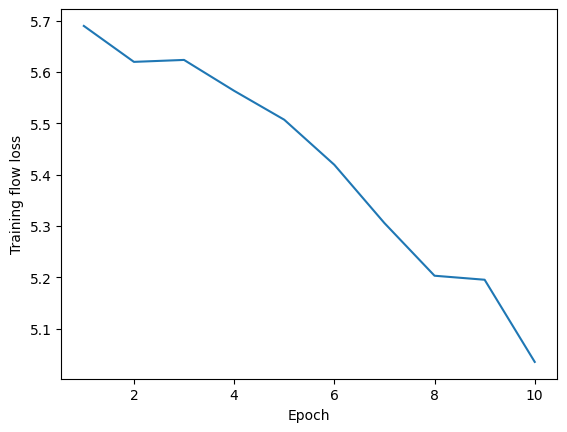

In [61]:
class AudioVisualTokenProjector(nn.Module):
    def __init__(
        self,
        video_dimension: int,
        audio_dimension: int,
        hidden_dimension: int,
        spatial_grid: tuple[int, int] | None = None,
    ) -> None:
        super().__init__()
        self.video_projection = nn.Linear(video_dimension, hidden_dimension)
        self.audio_projection = nn.Linear(audio_dimension, hidden_dimension)
        self.modality_embedding = nn.Embedding(2, hidden_dimension)
        self.hidden_dimension = hidden_dimension
        self.spatial_grid = spatial_grid
        self.register_buffer("spatial_positions", None, persistent=False)

    @jaxtyped(typechecker=beartype)
    def forward(
        self,
        video: Float[Tensor, "batch time patch video_feature"],
        audio: Float[Tensor, "batch time audio_feature"],
        frame_start: int,
        action_embeddings: Float[Tensor, "batch time hidden"] | None = None,
    ) -> Float[Tensor, "batch token_time hidden"]:
        positions = frame_position_embeddings(
            video, self.hidden_dimension, frame_start, frame_start + video.shape[1]
        )
        positions = rearrange(positions, "time hidden -> 1 time hidden")
        if action_embeddings is not None:
            positions = positions + action_embeddings

        video_tokens = (
            self.video_projection(video)
            + self.modality_embedding.weight[0]
            + positions[:, :, None]
        )
        if self.spatial_grid is not None:
            assert video.shape[2] == math.prod(self.spatial_grid)
            if self.spatial_positions is None:
                self.spatial_positions = get_2d_sincos_pos_embed(
                    self.hidden_dimension,
                    self.spatial_grid,
                    device=video.device,
                    output_type="pt",
                ).to(video)
            video_tokens = video_tokens + self.spatial_positions[None, None]

        audio_tokens = (
            self.audio_projection(audio)
            + self.modality_embedding.weight[1]
            + positions
        )
        return rearrange(
            torch.cat((video_tokens, audio_tokens[:, :, None]), dim=2),
            "batch time token hidden -> batch (time token) hidden",
        )


def train(
    ex_cnt: int = 5,
    epochs: int = 10,
) -> tuple[nn.ModuleDict, list[float]]:
    assert ex_cnt > 0 and epochs > 0
    device = 'cuda' if torch.cuda.is_available else 'cpu'
    ctx_frames: int = 16
    tgt_frames: int = 8
    tot_frames: int = ctx_frames + tgt_frames

    audio_encoder = (
        EncodecModel.from_pretrained("facebook/encodec_24khz")
        .to(device=device, dtype=torch.float32)
        .eval()
        .requires_grad_(False)
    )

    # putting it here,
    #https://stackoverflow.com/questions/58151507/why-pytorch-officially-use-mean-0-485-0-456-0-406-and-std-0-229-0-224-0-2
    video_encoder = DinoVideoEncoder(
        model_id="vit_small_patch16_dinov3.lvd1689m",
        pretrained=True,
        image_size=128,
        layer_numbers=(3, 6, 9, 12),
        mean=(0.485, 0.456, 0.406),
        standard_deviation=(0.229, 0.224, 0.225),
        frozen=True,
    ).to(device=device, dtype=torch.float32)

    video_clips: list[Tensor] = []
    audio_clips: list[Tensor] = []
    #TODO: use the cached ones instead to avoid waiting
    av_stream = stream_hf_av(count=ex_cnt, total_steps=tot_frames)

    with torch.no_grad():
        for batch in tqdm(av_stream, total=ex_cnt, desc="Encoding clips..."):
            v = video_encoder(batch["frames"].to(device))
            waveform = batch["waveform"].to(device)

            # split l,r
            mono_channels = rearrange(
                waveform, "batch channel sample -> (batch channel) 1 sample"
            )

            # ctx audio is wave * sr / fps
            context_samples = ctx_frames * 24_000 // 30

            # hide future audio
            observed_audio = audio_encoder.encoder(mono_channels[..., :context_samples])
            complete_audio = audio_encoder.encoder(mono_channels)

            # should be 5 tensor as we assert in prior cell
            assert observed_audio.shape[-1] == ctx_frames // 2 * 5
            assert complete_audio.shape[-1] == tot_frames // 2 * 5

            # reconstruct wave
            a = torch.cat(
                (
                    observed_audio,
                    complete_audio[..., observed_audio.shape[-1]:],
                ),
                dim=-1,
            )

            v = rearrange(
                v,
                "batch (time phase) patch feature -> batch time patch (phase feature)",
                phase=2,
            )
            a = rearrange(
                a,
                "(batch channel) feature (time phase) -> batch time (channel phase feature)",
                channel=waveform.shape[1],
                phase=5,
            )
            assert v.shape[:2] == a.shape[:2], (f"vid: {tuple(v.shape)}', aud: {tuple(a.shape)}")

            video_clips.append(v.cpu())
            audio_clips.append(a.cpu())

    v_feats = torch.cat(video_clips)
    a_feats = torch.cat(audio_clips)
    assert v_feats.shape[0] == ex_cnt

    v_sigma, v_mu = torch.std_mean(
        v_feats, dim=(0, 1, 2), correction=0
    )
    a_sigma, a_mu = torch.std_mean(
        a_feats, dim=(0, 1), correction=0
    )
    norm = AudioVisualNormalizer(
        v_mu,
        v_sigma.clamp_min(1e-6),
        a_mu,
        a_sigma.clamp_min(1e-6),
    )
    train_dl = DataLoader(
        TensorDataset(
            norm.normalize_video(v_feats),
            norm.normalize_audio(a_feats),
        ),
        batch_size=1,
        shuffle=True,
        num_workers=0,
    )

    pred = AudioVisualFlowPredictor(
        video_dimension=v_feats.shape[-1],
        audio_dimension=a_feats.shape[-1],
        action_dimension=32,
        backbone_hidden_dimension=128,
        backbone_heads=4,
        backbone_layers=2,
        diffusion_head_hidden_dimension=256,
        diffusion_head_heads=4,
        diffusion_head_layers=1,
        mlp_ratio=2.0,
        dropout=0.0,
        noise_time_embedding="gaussian_fourier",
        spatial_grid=(8, 8),
    ).to(device=device, dtype=torch.float32).train()

    transport = AudioVisualFlowTransport(TransportConfig())
    optimizer = torch.optim.AdamW(
        [
            parameter
            for parameter in pred.parameters()
            if parameter.requires_grad
        ],
        lr=1e-4,
    )
    losses: list[float] = []

    for epoch in range(epochs):
        epoch_losses: list[float] = []
        for v, a in train_dl:
            optimizer.zero_grad(set_to_none=True)
            loss = flow_matching_loss(
                transport,
                pred,
                v.to(device),
                a.to(device),
                context_steps=ctx_frames // 2,
                actions=None,
            )
            assert torch.isfinite(loss)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(pred.parameters(), 1.0)
            optimizer.step()
            epoch_losses.append(loss.item())

        losses.append(sum(epoch_losses) / len(epoch_losses))
        print(f"Epoch {epoch + 1}: loss={losses[-1]:.4f}")

    return nn.ModuleDict(
        {
            "audio_encoder": audio_encoder,
            "video_encoder": video_encoder,
            "pred": pred,
            "norm": norm.to(device),
        }
    ), losses


train_out, losses = train()
plt.plot(range(1, len(losses) + 1), losses)
plt.xlabel("Epoch")
plt.ylabel("Training flow loss")
plt.show()

##

# Postraining